# Previsão de Abandono em Planos de Academia
**Comparação de Modelos de Machine Learning Clássico e Segmentação de Clientes com K-Means**

Dataset: *Gym Customers Features and Churn* (Kaggle) — `gym_churn_us.csv`

## 0. Definição do problema
- **O que prevemos?** Se o cliente vai abandonar o plano no próximo mês (`Churn` = 1) → **classificação binária**.
- **Quem usa?** Equipe de retenção/gestão da academia, para priorizar contato e ofertas.
- **Qual erro custa mais?** **FN** (cliente que sai e não foi detectado) custa a mensalidade perdida; **FP** custa só uma ação de retenção. → **Recall da classe 1** é a métrica principal, com F1 e ROC-AUC de apoio.
- **ML é a escolha certa?** Será testado contra uma **regra heurística** e contra o classificador **"sempre 0"**.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Análise Exploratória de Dados (EDA)

In [2]:
df = pd.read_csv("gym_churn_us.csv")
print(df.shape)
df.head()

(4000, 14)


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

In [4]:
print("NaN:", df.isna().sum().sum(), "| Duplicadas:", df.duplicated().sum())
df.describe().T.round(2)

NaN: 0 | Duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
gender,4000.0,0.51,0.50,0.00,0.00,1.00,1.00,1.00
Near_Location,4000.0,0.85,0.36,0.00,1.00,1.00,1.00,1.00
Partner,4000.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
Promo_friends,4000.0,0.31,0.46,0.00,0.00,0.00,1.00,1.00
Phone,4000.0,0.90,0.30,0.00,1.00,1.00,1.00,1.00
Contract_period,4000.0,4.68,4.55,1.00,1.00,1.00,6.00,12.00
Group_visits,4000.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
Age,4000.0,29.18,3.26,18.00,27.00,29.00,31.00,41.00
Avg_additional_charges_total,4000.0,146.94,96.36,0.15,68.87,136.22,210.95,552.59
Month_to_end_contract,4000.0,4.32,4.19,1.00,1.00,1.00,6.00,12.00


### 1.1 Desbalanceamento da variável-alvo

Churn
0    2939
1    1061
Name: count, dtype: int64
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


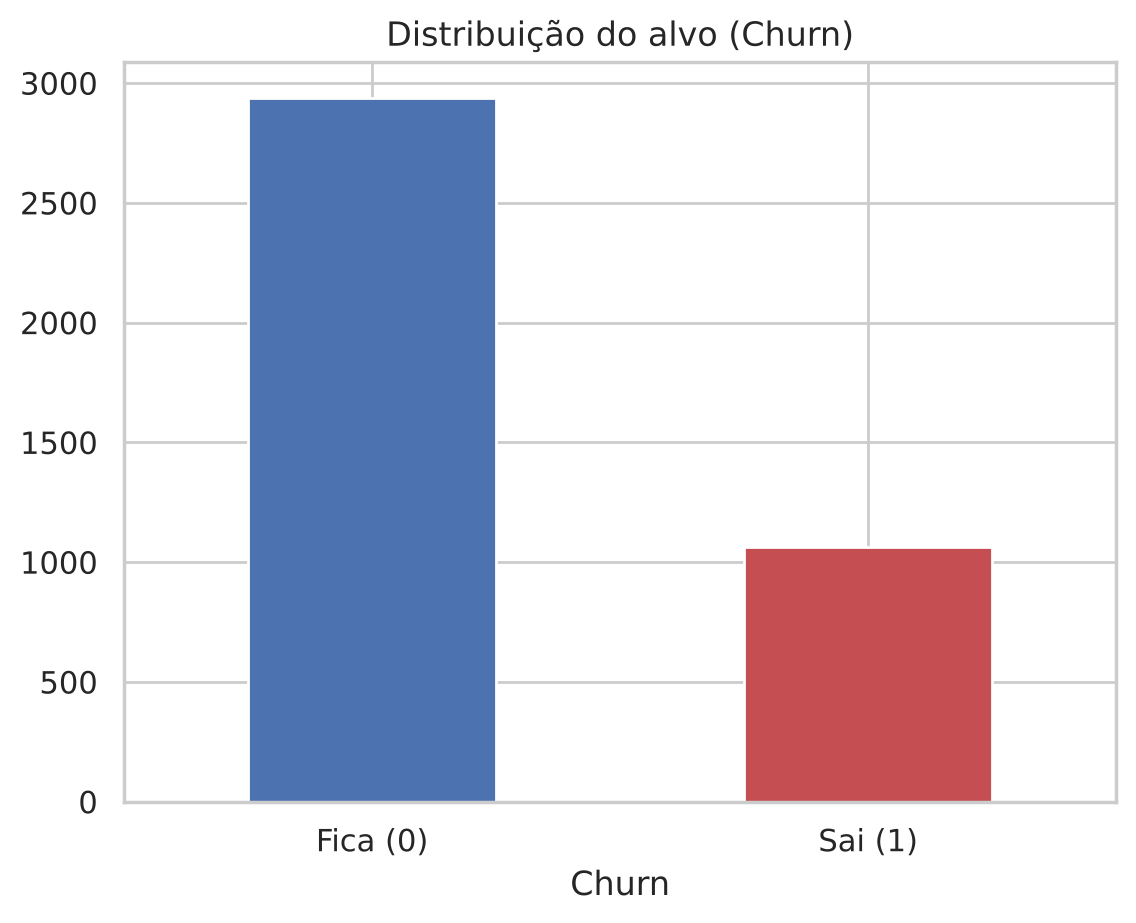

In [5]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))
df["Churn"].value_counts().plot.bar(color=["#4C72B0", "#C44E52"])
plt.title("Distribuição do alvo (Churn)"); plt.xticks([0, 1], ["Fica (0)", "Sai (1)"], rotation=0); plt.show()

26,5% de churn → desbalanceamento moderado. Tratamento: split **estratificado**, `class_weight='balanced'` e métricas focadas na classe 1. O baseline "sempre 0" acerta 73,5% e encontra **zero** clientes que saem — por isso Accuracy sozinha não serve.

### 1.2 Distribuições e outliers

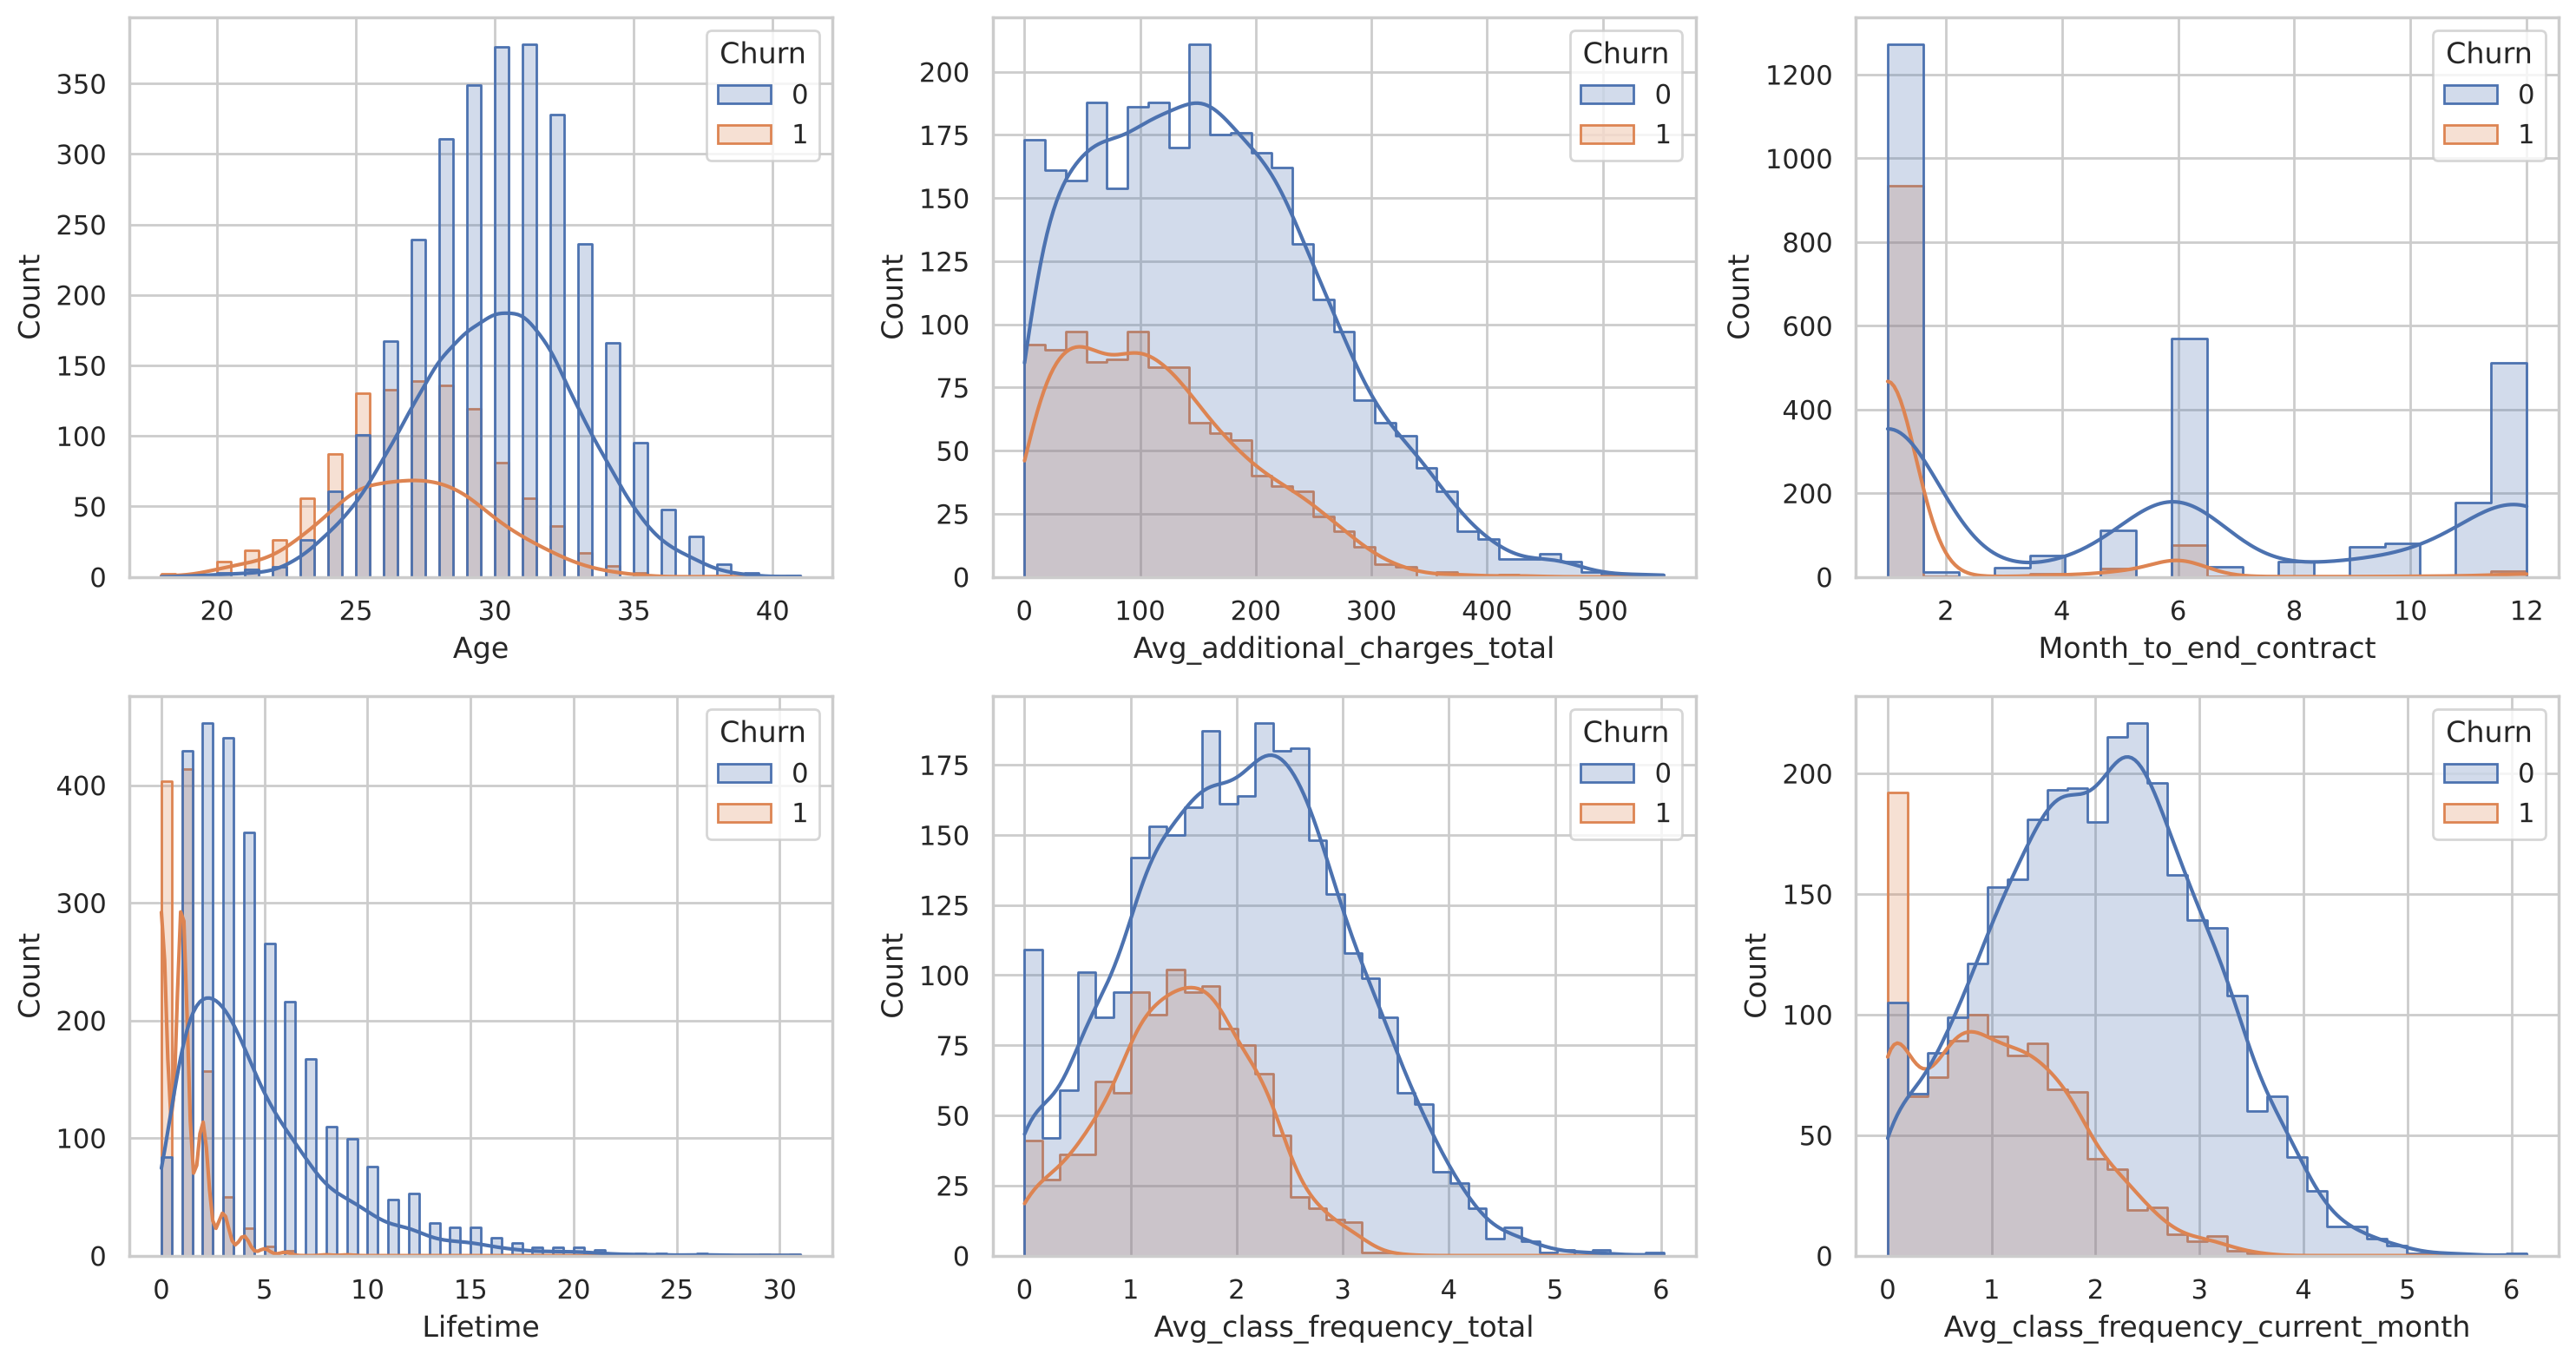

In [6]:
num = ["Age", "Avg_additional_charges_total", "Month_to_end_contract", "Lifetime",
       "Avg_class_frequency_total", "Avg_class_frequency_current_month"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), num):
    sns.histplot(data=df, x=c, hue="Churn", kde=True, ax=a, element="step")
plt.tight_layout(); plt.show()

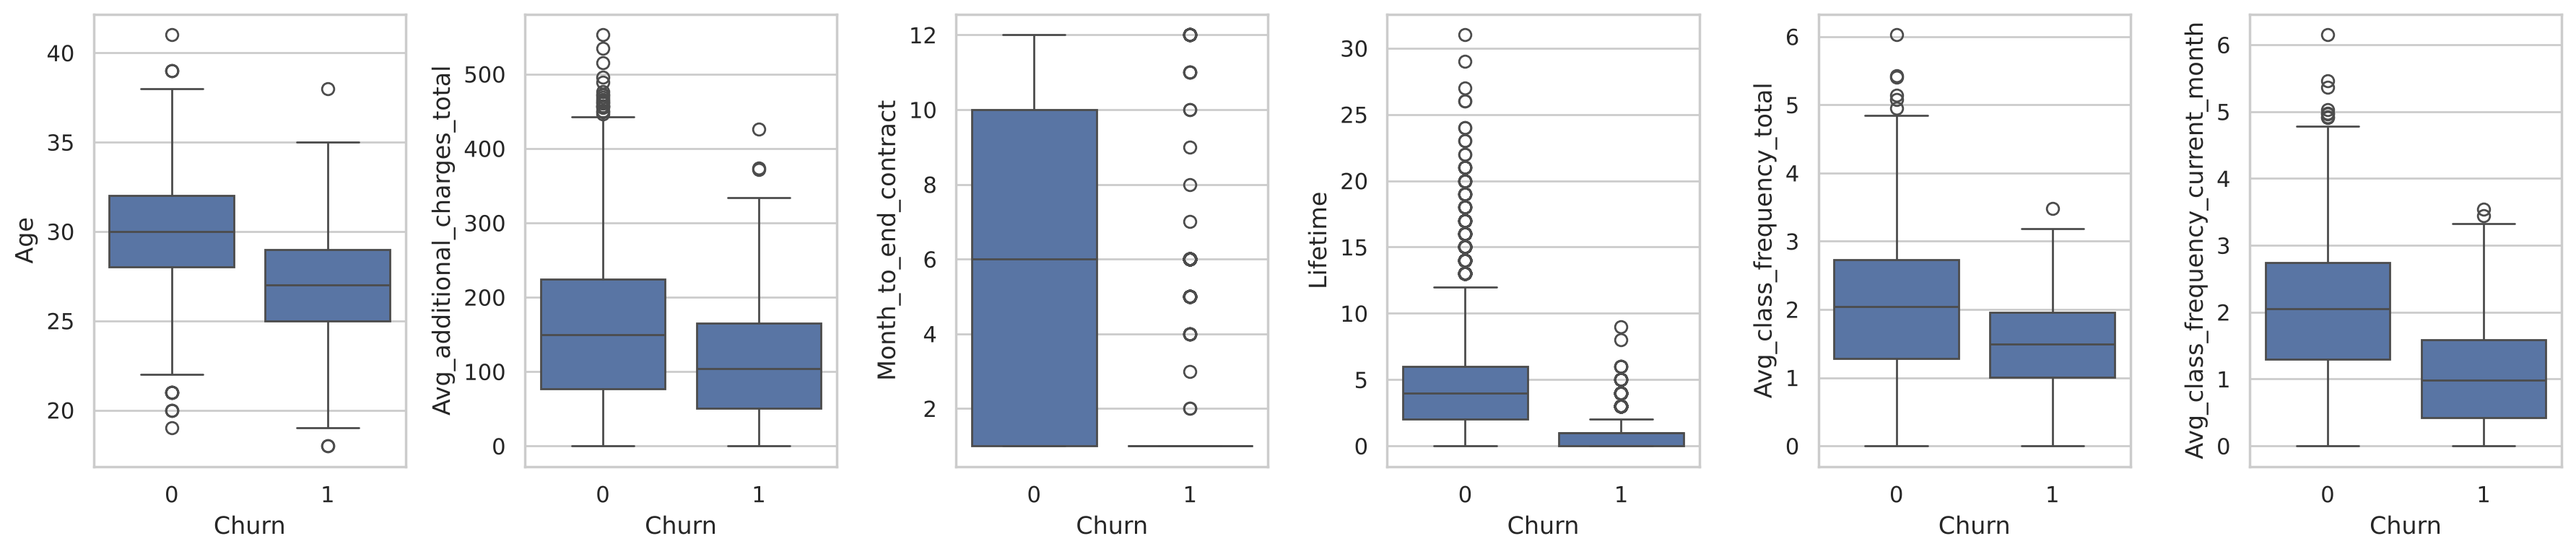

In [7]:
fig, ax = plt.subplots(1, 6, figsize=(18, 4))
for a, c in zip(ax, num):
    sns.boxplot(data=df, x="Churn", y=c, ax=a)
plt.tight_layout(); plt.show()

In [8]:
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

pd.DataFrame({"outliers_IQR": {c: outliers_iqr(df[c]) for c in num},
              "assimetria": df[num].skew().round(2)})

,outliers_IQR,assimetria
Age,32,-0.06
Avg_additional_charges_total,29,0.62
Month_to_end_contract,0,0.81
Lifetime,192,1.93
Avg_class_frequency_total,16,0.25
Avg_class_frequency_current_month,8,0.26


Outliers em `Lifetime` (192), `Age` (32), `Avg_additional_charges_total` (29) e frequências (16/8). São valores **plausíveis** (clientes antigos, gasto alto), não erros → **mantidos**. `Lifetime` tem forte assimetria → candidato a `log1p` (usado no K-Means).

### 1.3 Variáveis binárias e contrato

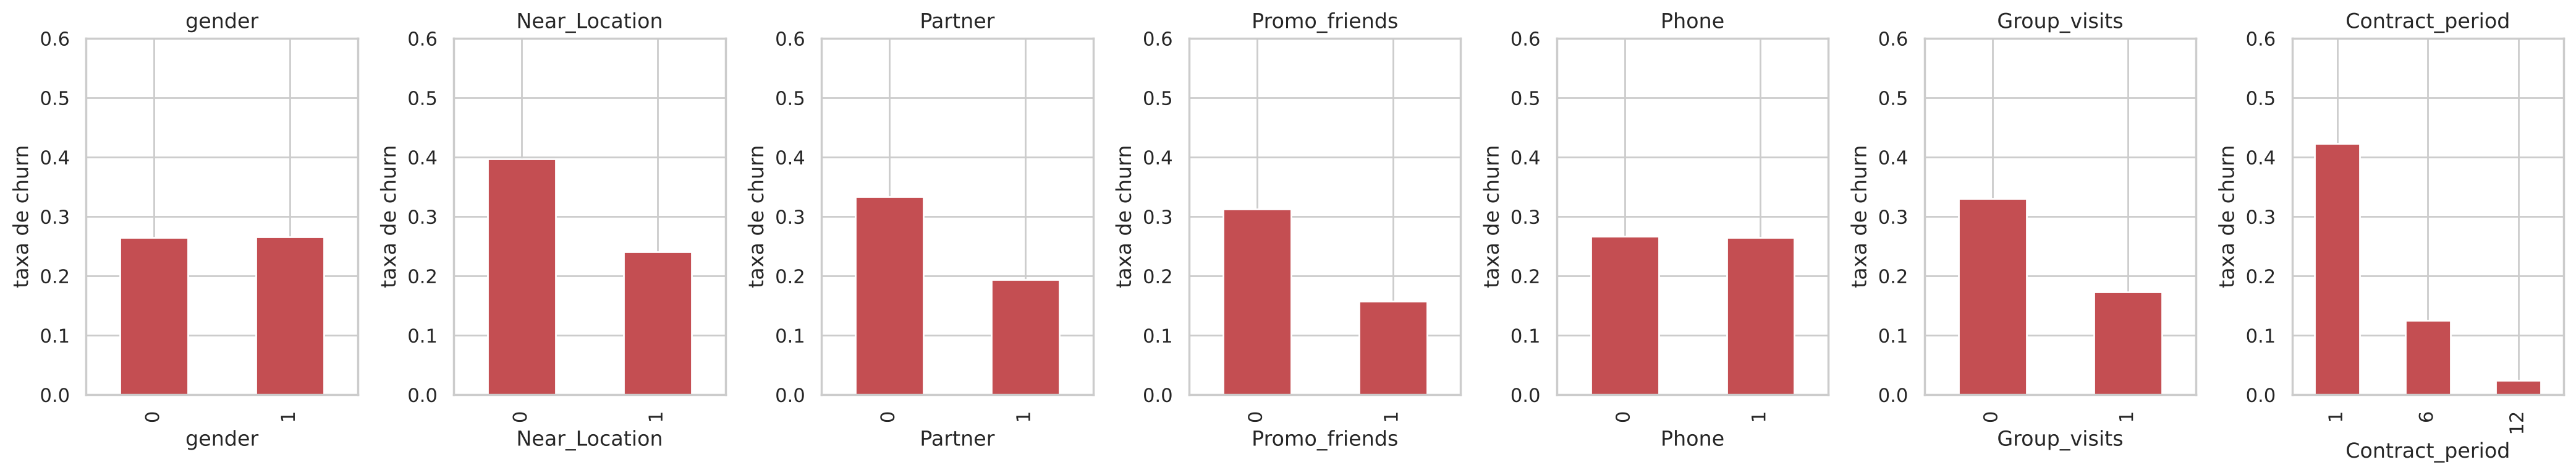

In [9]:
cat = ["gender", "Near_Location", "Partner", "Promo_friends", "Phone", "Group_visits", "Contract_period"]
fig, ax = plt.subplots(1, 7, figsize=(21, 4))
for a, c in zip(ax, cat):
    df.groupby(c)["Churn"].mean().plot.bar(ax=a, color="#C44E52")
    a.set_title(c); a.set_ylabel("taxa de churn"); a.set_ylim(0, .6)
plt.tight_layout(); plt.show()

In [10]:
df.groupby("Churn").mean().T.round(2)

Churn,0,1
gender,0.51,0.51
Near_Location,0.87,0.77
Partner,0.53,0.36
Promo_friends,0.35,0.18
Phone,0.90,0.90
Contract_period,5.75,1.73
Group_visits,0.46,0.27
Age,29.98,26.99
Avg_additional_charges_total,158.45,115.08
Month_to_end_contract,5.28,1.66


### 1.4 Correlações

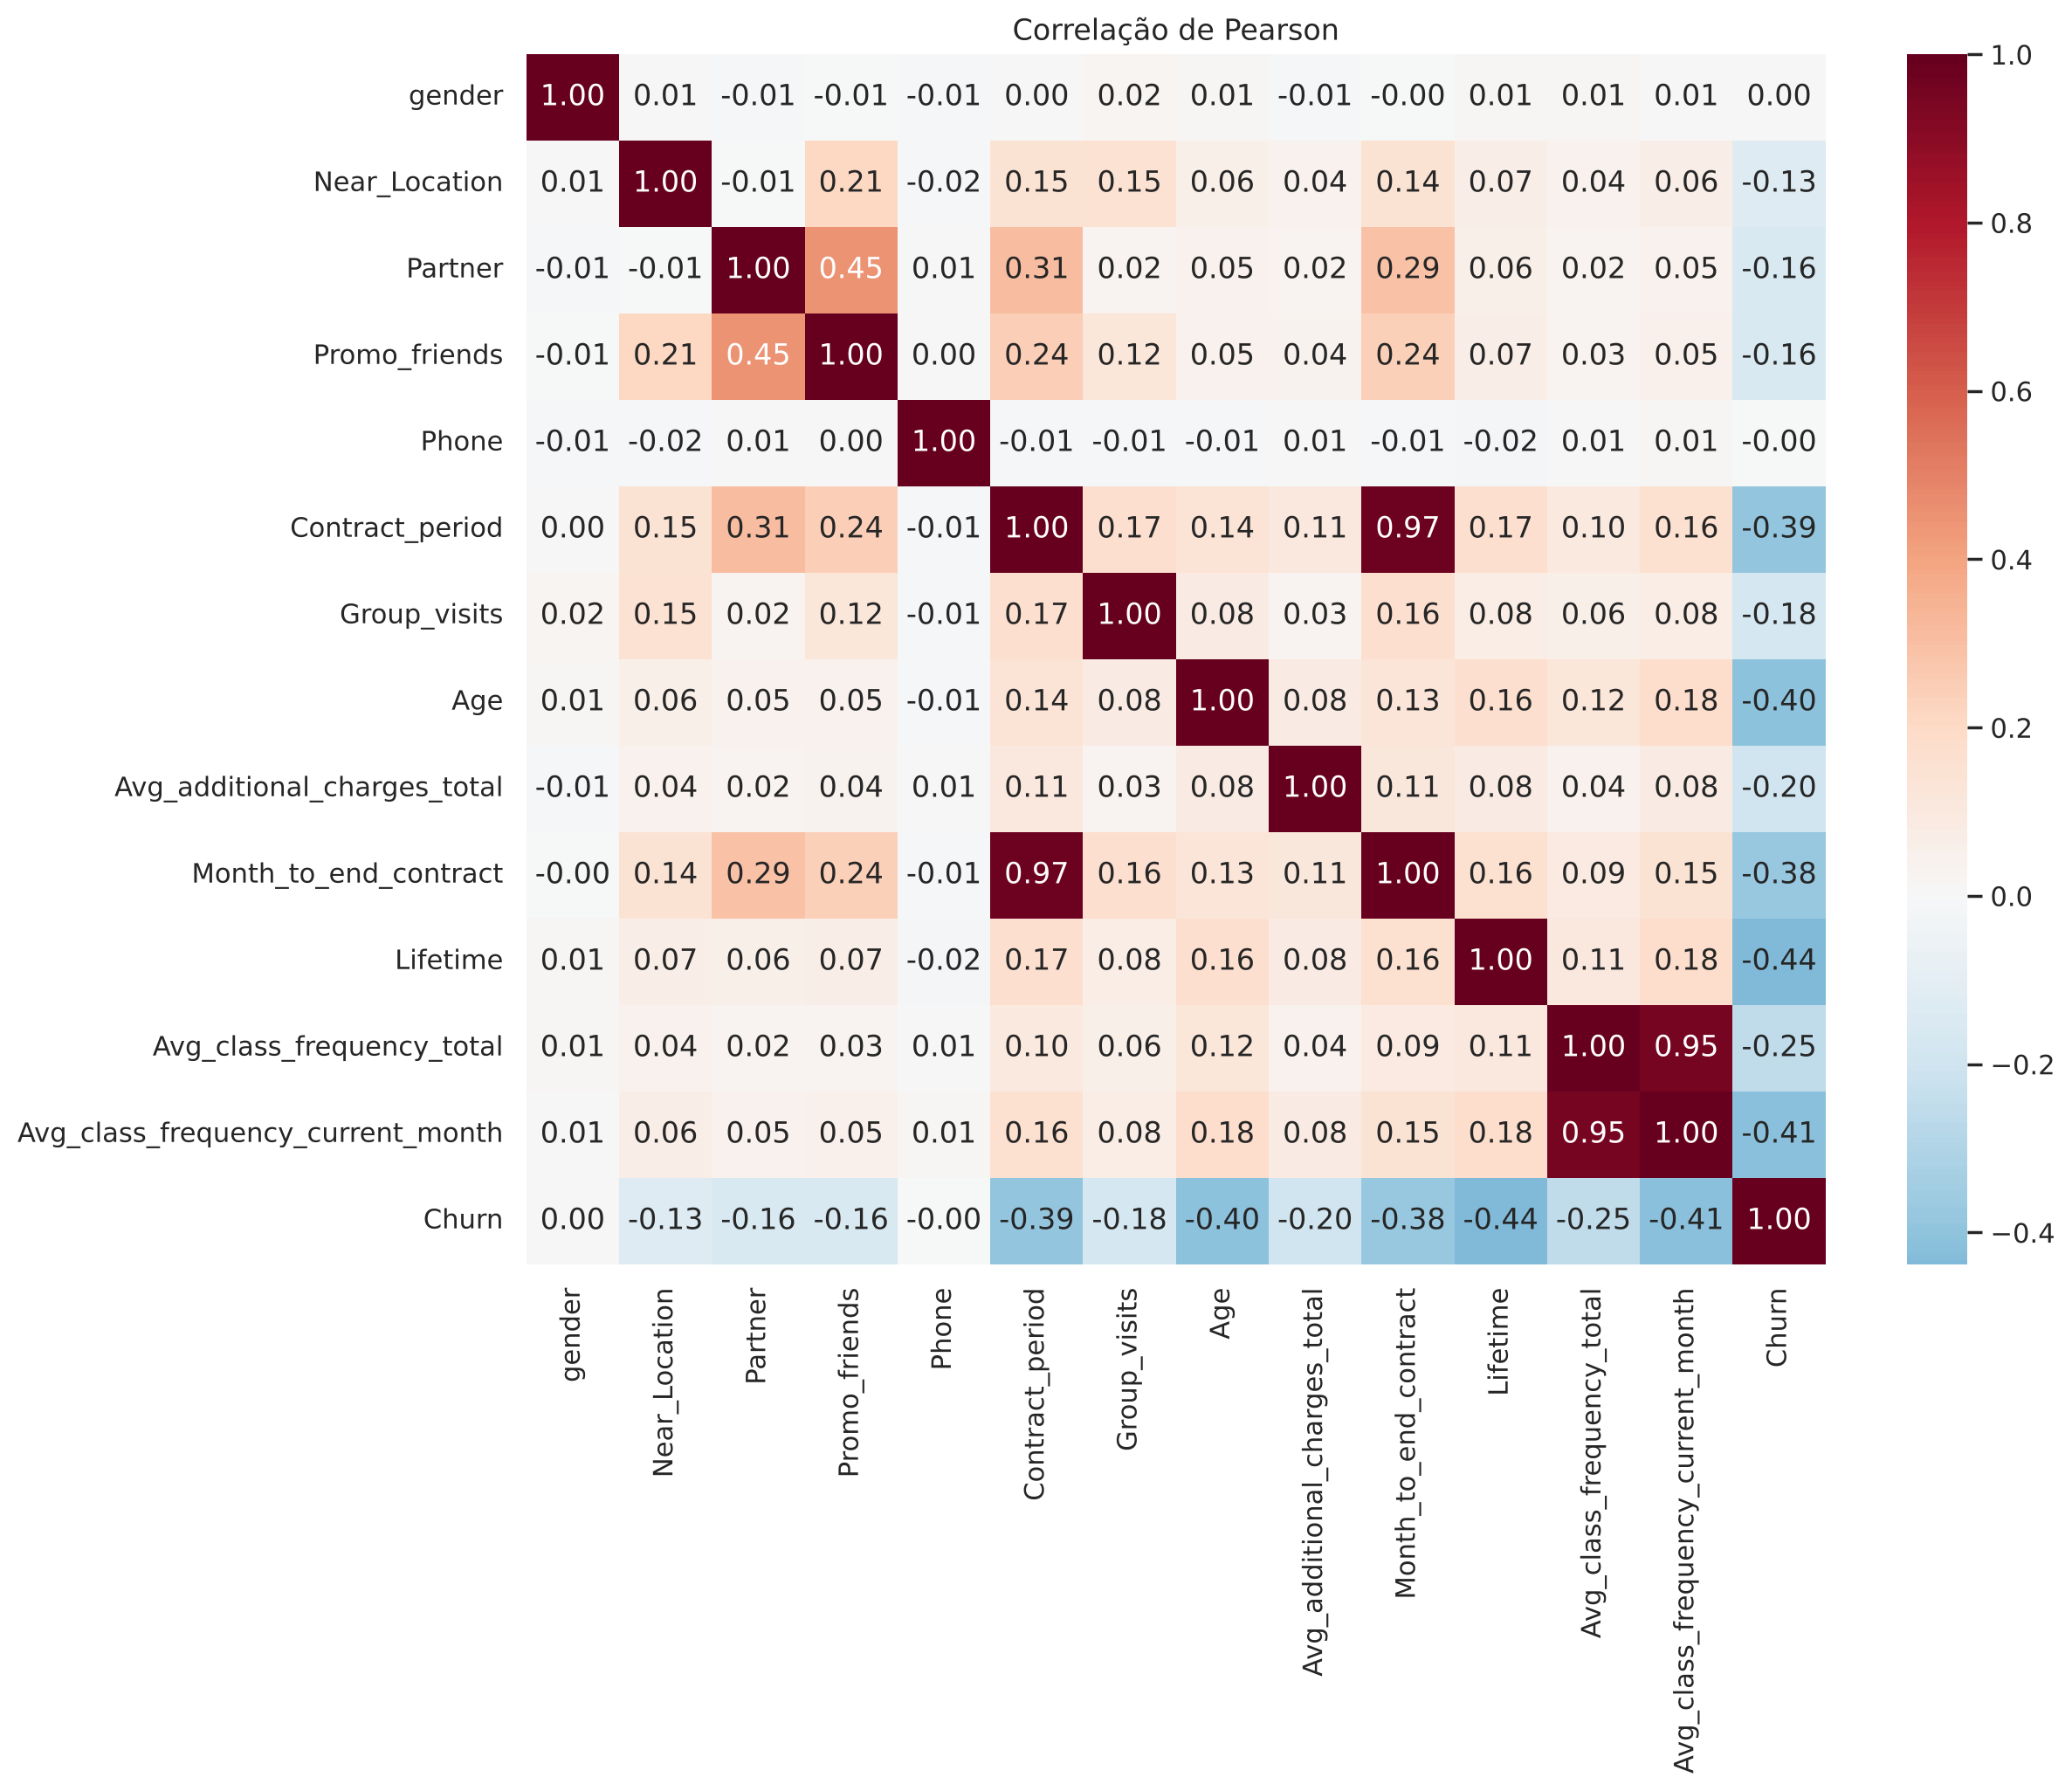

In [11]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlação de Pearson"); plt.show()

In [12]:
df.corr()["Churn"].drop("Churn").sort_values()

Lifetime                            -0.438220
Avg_class_frequency_current_month   -0.412348
Age                                 -0.404735
Contract_period                     -0.389984
Month_to_end_contract               -0.381393
Avg_class_frequency_total           -0.249715
Avg_additional_charges_total        -0.198697
Group_visits                        -0.175325
Promo_friends                       -0.162233
Partner                             -0.157986
Near_Location                       -0.128098
Phone                               -0.001177
gender                               0.000708
Name: Churn, dtype: float64

- Mais associados ao churn (negativo = protege): `Lifetime` (−0,44), frequência no mês (−0,41), `Age` (−0,40), `Contract_period` (−0,39), `Month_to_end_contract` (−0,38).
- `gender` e `Phone` ≈ 0 → pouco informativos.
- **Multicolinearidade:** `Contract_period` × `Month_to_end_contract` (0,97) e frequência total × mês atual (0,95). Afeta Logística (coeficientes instáveis) e distâncias (KNN/SVM/K-Means contam a mesma informação duas vezes).

## 2. Pré-processamento e Feature Engineering
### 2.1 Diagnóstico e estratégias de pré-processamento
| Item | Diagnóstico | Estratégia |
|---|---|---|
| Valores ausentes | 0 | Nenhuma imputação necessária (pipeline aceita `SimpleImputer(median)` por segurança) |
| Outliers | Plausíveis | Mantidos |
| Categóricas | `Contract_period` (1/6/12) | One-Hot |
| Binárias | 7 colunas 0/1 | Mantidas como estão |
| Escala | Idade ~30, gasto ~150, frequência ~2 | `StandardScaler` (KNN, SVM, Logística, K-Means); árvores não precisam |
| Desbalanceamento | 26,5% | Estratificação + `class_weight` |
| Redundância | 2 pares com r > 0,95 | Substituídos por features derivadas |

### 2.2 Engenharia de atributos
- `freq_drop` = frequência do mês atual − frequência total → **queda recente de uso** (sinal clássico de abandono).
- `contrato_restante_pct` = meses restantes / duração do contrato → **quão perto do fim** o cliente está, independente do tipo de plano.

Com elas, removemos `Avg_class_frequency_total` e `Month_to_end_contract` (informação preservada nas novas colunas, sem r > 0,95).

In [13]:
def criar_features(d):
    d = d.copy()
    d["freq_drop"] = d["Avg_class_frequency_current_month"] - d["Avg_class_frequency_total"]
    d["contrato_restante_pct"] = d["Month_to_end_contract"] / d["Contract_period"]
    return d.drop(columns=["Avg_class_frequency_total", "Month_to_end_contract"])

dfe = criar_features(df)
dfe.groupby("Churn")[["freq_drop", "contrato_restante_pct"]].mean().round(3)

,freq_drop,contrato_restante_pct
Churn,,
0,0.003,0.953
1,-0.430,0.991


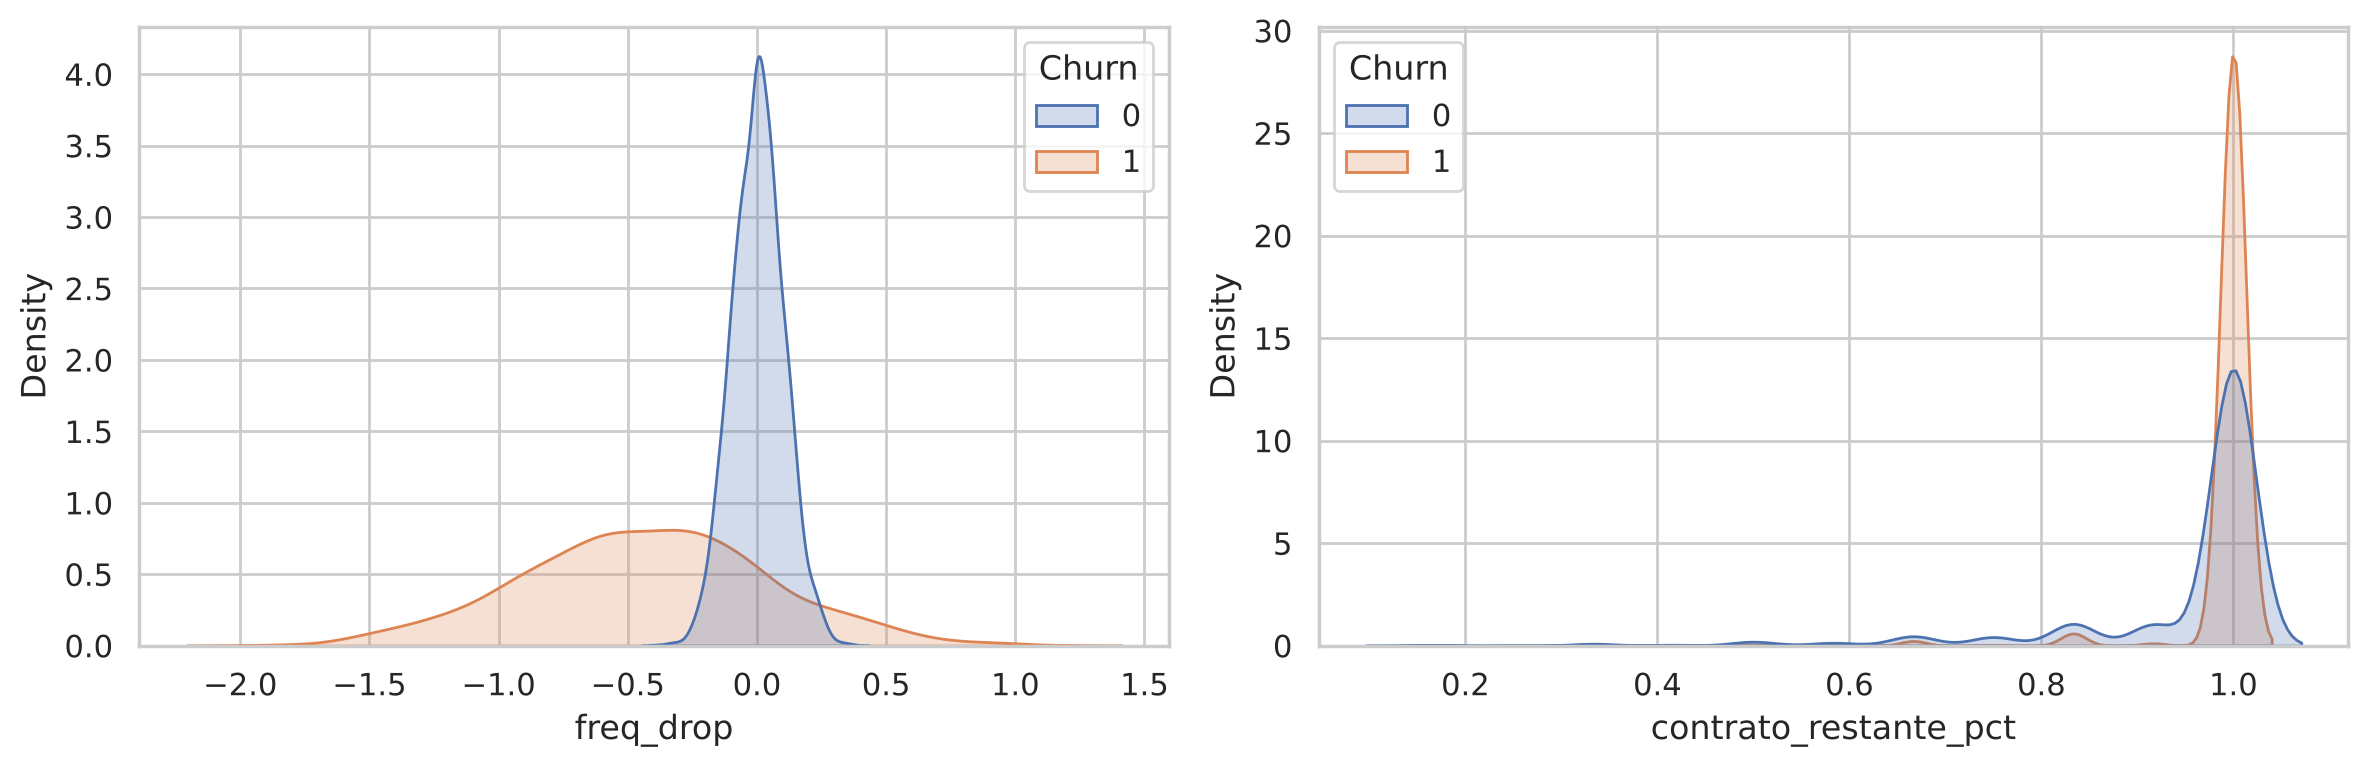

Maior |r| restante: 0.452


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=dfe, x="freq_drop", hue="Churn", common_norm=False, fill=True, ax=ax[0])
sns.kdeplot(data=dfe, x="contrato_restante_pct", hue="Churn", common_norm=False, fill=True, ax=ax[1])
plt.tight_layout(); plt.show()
c = dfe.drop(columns="Churn").corr().abs()
print("Maior |r| restante:", c.where(np.triu(np.ones(c.shape), 1).astype(bool)).stack().max().round(3))

### 2.3 Divisão dos dados
Não há datas nem IDs repetidos (uma linha = um cliente) → split **aleatório estratificado**: **60% treino / 20% validação / 20% teste**.
- **Treino:** ajuste dos modelos e GridSearchCV (validação cruzada estratificada 5-fold).
- **Validação:** escolha do limiar de decisão e comparação entre famílias.
- **Teste:** usado **uma única vez** no final, para o resultado reportado.

In [15]:
X = dfe.drop(columns="Churn")
y = dfe["Churn"]
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
for n, yy in [("treino", y_train), ("validação", y_val), ("teste", y_test)]:
    print(f"{n:10s} {len(yy):5d} linhas | churn = {yy.mean():.3f}")

treino      2400 linhas | churn = 0.265
validação    800 linhas | churn = 0.265
teste        800 linhas | churn = 0.265


### 2.4 Pipeline de pré-processamento
O `StandardScaler` aprende média e desvio. Se aprender com validação/teste, o modelo "vê" o futuro (**vazamento de dados**) e a avaliação fica otimista. Dentro de um `Pipeline`, o `fit` acontece só no treino (e só no fold de treino durante a CV); validação e teste recebem apenas `transform`.

In [16]:
from sklearn.impute import SimpleImputer

col_cat = ["Contract_period"]
col_num = [c for c in X.columns if c not in col_cat]

prep_escala = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), col_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat),
])
prep_arvore = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), col_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat),
])

Xt = prep_escala.fit(X_train).transform(X_train)
nomes = prep_escala.get_feature_names_out()
pd.DataFrame(Xt, columns=nomes).describe().T[["mean", "std"]].round(2)

,mean,std
num__gender,-0.00,1.00
num__Near_Location,-0.00,1.00
num__Partner,0.00,1.00
num__Promo_friends,0.00,1.00
num__Phone,0.00,1.00
num__Group_visits,0.00,1.00
num__Age,0.00,1.00
num__Avg_additional_charges_total,-0.00,1.00
num__Lifetime,0.00,1.00
num__Avg_class_frequency_current_month,0.00,1.00


**Resultado:** colunas numéricas com média 0 e desvio 1 no treino; `Contract_period` virou 3 colunas binárias. Dois pré-processadores:
- `prep_escala` → Logística, KNN, SVM (sensíveis a distância/escala).
- `prep_arvore` → Árvore e ensembles de árvores (invariantes à escala).

## 3. Modelagem supervisionada
### 3.1 Protocolo de comparação
- Todos os modelos usam **o mesmo split**, a **mesma CV** (`StratifiedKFold` 5-fold, semente fixa) e as **mesmas métricas**.
- Otimização com `GridSearchCV` no **treino**; métrica de escolha = **F1 da classe 1** (equilibra Recall e Precision — otimizar só Recall levaria ao modelo trivial "todos saem").
- Comparação entre modelos na **validação**. O **teste** fica guardado para a seção 4.

In [17]:
import time
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultados, modelos = [], {}

def avaliar(nome, modelo, X_, y_):
    p = modelo.predict(X_)
    proba = modelo.predict_proba(X_)[:, 1] if hasattr(modelo, "predict_proba") else None
    return {"modelo": nome,
            "Accuracy": accuracy_score(y_, p),
            "Precision": precision_score(y_, p, zero_division=0),
            "Recall": recall_score(y_, p),
            "F1": f1_score(y_, p),
            "ROC_AUC": roc_auc_score(y_, proba) if proba is not None else np.nan}

def treinar(nome, pipe, grid):
    t = time.time()
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    modelos[nome] = gs.best_estimator_
    r = avaliar(nome, gs.best_estimator_, X_val, y_val)
    r["F1_CV"] = gs.best_score_; r["tempo_s"] = time.time() - t
    resultados.append(r)
    print(f"{nome}: {gs.best_params_} | F1 CV = {gs.best_score_:.3f} | F1 val = {r['F1']:.3f}")
    return gs

### 3.2 Baselines
- **Sempre 0:** prevê que ninguém sai.
- **Regra heurística:** "sai quem tem contrato de 1 mês **e** está há ≤ 2 meses na academia" — o tipo de regra que um gerente usaria.

In [18]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
resultados.append(avaliar("Baseline: sempre 0", dummy, X_val, y_val))

class Heuristica:
    def predict(self, X_):
        return ((X_["Contract_period"] == 1) & (X_["Lifetime"] <= 2)).astype(int).values

resultados.append(avaliar("Baseline: regra heurística", Heuristica(), X_val, y_val))
pd.DataFrame(resultados).set_index("modelo").round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC
modelo,,,,,
Baseline: sempre 0,0.735,0.000,0.00,0.000,0.5
Baseline: regra heurística,0.848,0.669,0.84,0.745,NaN


O "sempre 0" tem boa Accuracy e **Recall = 0** (não encontra ninguém). A regra heurística já encontra boa parte dos que saem, mas com muitos falsos alarmes. **O ML só se justifica se superar a regra com folga** — é o que as próximas seções verificam.

### 3.3 Regressão Logística
- Escore linear $z = w^Tx + b$ → sigmoide $p = 1/(1+e^{-z})$ → classe 1 se $p \geq \tau$.
- **C:** inverso da regularização (C pequeno = pesos menores, modelo mais simples). **solver:** algoritmo de otimização. **max_iter:** limite de iterações para convergir.
- A sigmoide é curva, mas a **fronteira de decisão é linear** ($z = 0$).

In [19]:
from sklearn.linear_model import LogisticRegression
treinar("Regressão Logística",
        Pipeline([("prep", prep_escala), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__solver": ["lbfgs", "liblinear"]});

Regressão Logística: {'clf__C': 10, 'clf__solver': 'lbfgs'} | F1 CV = 0.843 | F1 val = 0.837


In [20]:
lr = modelos["Regressão Logística"]
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef)}).sort_values("coef").round(3)

,coef,odds_ratio
num__Lifetime,-3.769,0.023
cat__Contract_period_12,-2.677,0.069
num__Age,-1.223,0.294
num__freq_drop,-0.984,0.374
num__Avg_class_frequency_current_month,-0.981,0.375
cat__Contract_period_6,-0.828,0.437
num__Avg_additional_charges_total,-0.643,0.526
num__Group_visits,-0.291,0.748
num__Promo_friends,-0.227,0.797
num__contrato_restante_pct,-0.167,0.846


**Leitura das odds:** odds ratio < 1 reduz a chance de sair; > 1 aumenta. Como as variáveis estão padronizadas, o efeito é **por 1 desvio padrão**. Atenção: se as odds dobram, **p não dobra** (ex.: p = 0,20 → odds 0,25 → 0,50 → p = 0,33).

### 3.4 KNN
Classifica pelo voto dos K vizinhos mais próximos (distância Euclidiana/Manhattan) → **exige escala**. K pequeno = fronteira irregular (overfitting); K grande = fronteira suave (underfitting).

In [21]:
from sklearn.neighbors import KNeighborsClassifier
gs_knn = treinar("KNN",
        Pipeline([("prep", prep_escala), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": list(range(1, 52, 2)), "clf__weights": ["uniform", "distance"], "clf__p": [1, 2]})

KNN: {'clf__n_neighbors': 11, 'clf__p': 1, 'clf__weights': 'distance'} | F1 CV = 0.845 | F1 val = 0.851


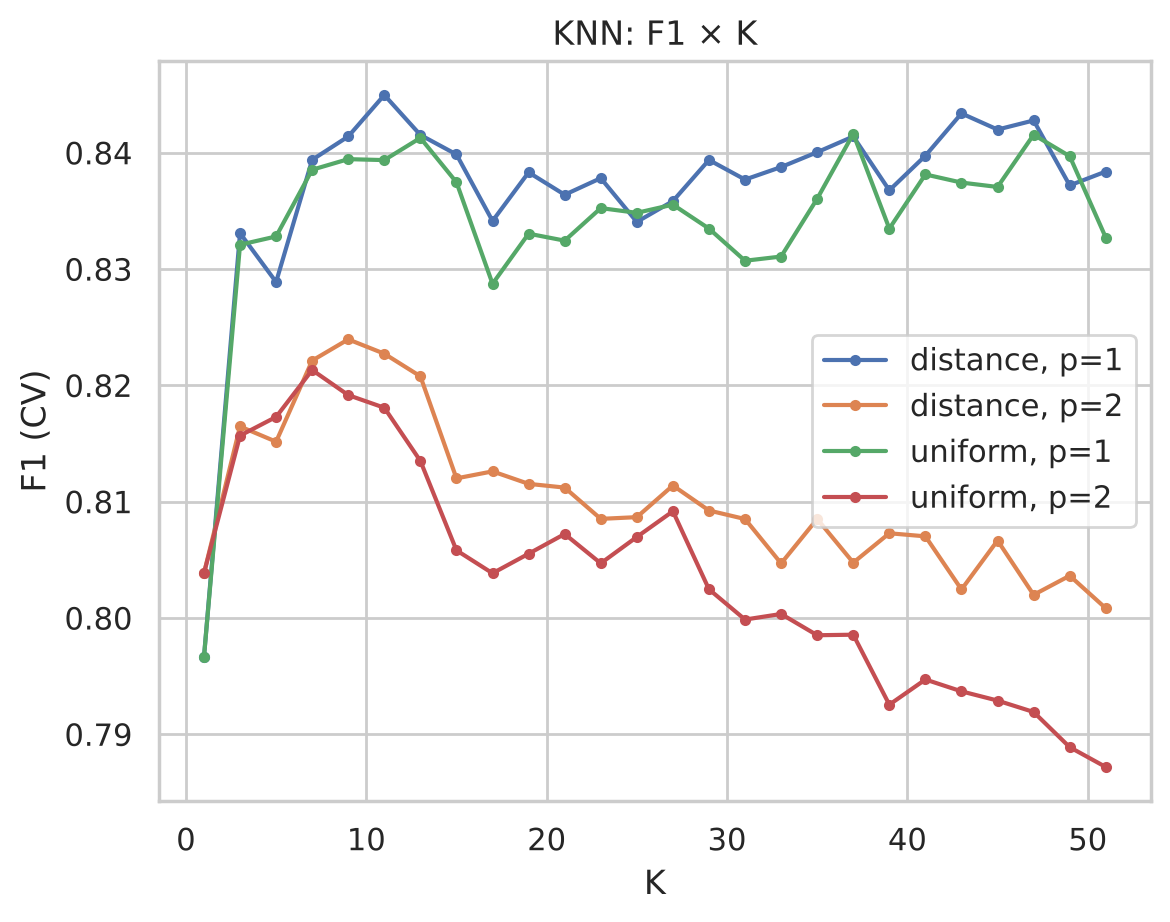

In [22]:
cvr = pd.DataFrame(gs_knn.cv_results_)
for (w, p_), g in cvr.groupby(["param_clf__weights", "param_clf__p"]):
    plt.plot(g["param_clf__n_neighbors"], g["mean_test_score"], marker=".", label=f"{w}, p={p_}")
plt.xlabel("K"); plt.ylabel("F1 (CV)"); plt.title("KNN: F1 × K"); plt.legend(); plt.show()

Não existe K mágico — o melhor K depende dos dados e é escolhido por validação cruzada. A curva mostra K muito pequeno instável e K muito grande perdendo desempenho.

### 3.5 SVM
Busca o hiperplano de **margem máxima**; só os **vetores de suporte** (pontos na margem) definem a fronteira. O **kernel** projeta os dados num espaço onde fiquem separáveis sem calcular a projeção explicitamente. **C:** penalidade por erro na margem; **gamma (RBF):** alcance de cada ponto.

In [23]:
from sklearn.svm import SVC
treinar("SVM linear",
        Pipeline([("prep", prep_escala), ("clf", SVC(kernel="linear", class_weight="balanced", probability=True, random_state=SEED))]),
        {"clf__C": [0.01, 0.1, 1, 10]})
gs_svm = treinar("SVM RBF",
        Pipeline([("prep", prep_escala), ("clf", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
        {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1, 1]})
print("Vetores de suporte (RBF):", modelos["SVM RBF"].named_steps["clf"].n_support_)

SVM linear: {'clf__C': 0.01} | F1 CV = 0.845 | F1 val = 0.833


SVM RBF: {'clf__C': 100, 'clf__gamma': 0.01} | F1 CV = 0.888 | F1 val = 0.870
Vetores de suporte (RBF): [270 114]


Comparamos kernel **linear** (fronteira reta, mais interpretável) e **RBF** (fronteira curva). Se o RBF não superar o linear com folga, os dados são aproximadamente linearmente separáveis.

### 3.6 Árvore de Decisão
Divide os dados por testes em atributos que mais reduzem a impureza (Gini/Entropia). Sem limite, decora o treino → controlamos com **max_depth**, **min_samples_leaf** e poda por **ccp_alpha**.

In [24]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
treinar("Árvore de Decisão",
        Pipeline([("prep", prep_arvore), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
        {"clf__max_depth": [3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 5, 10, 20],
         "clf__criterion": ["gini", "entropy"], "clf__ccp_alpha": [0, 0.001, 0.005]});

Árvore de Decisão: {'clf__ccp_alpha': 0.005, 'clf__criterion': 'entropy', 'clf__max_depth': 8, 'clf__min_samples_leaf': 1} | F1 CV = 0.876 | F1 val = 0.884


Árvore sem limite: profundidade 16 | F1 treino 1.0 | F1 val 0.882


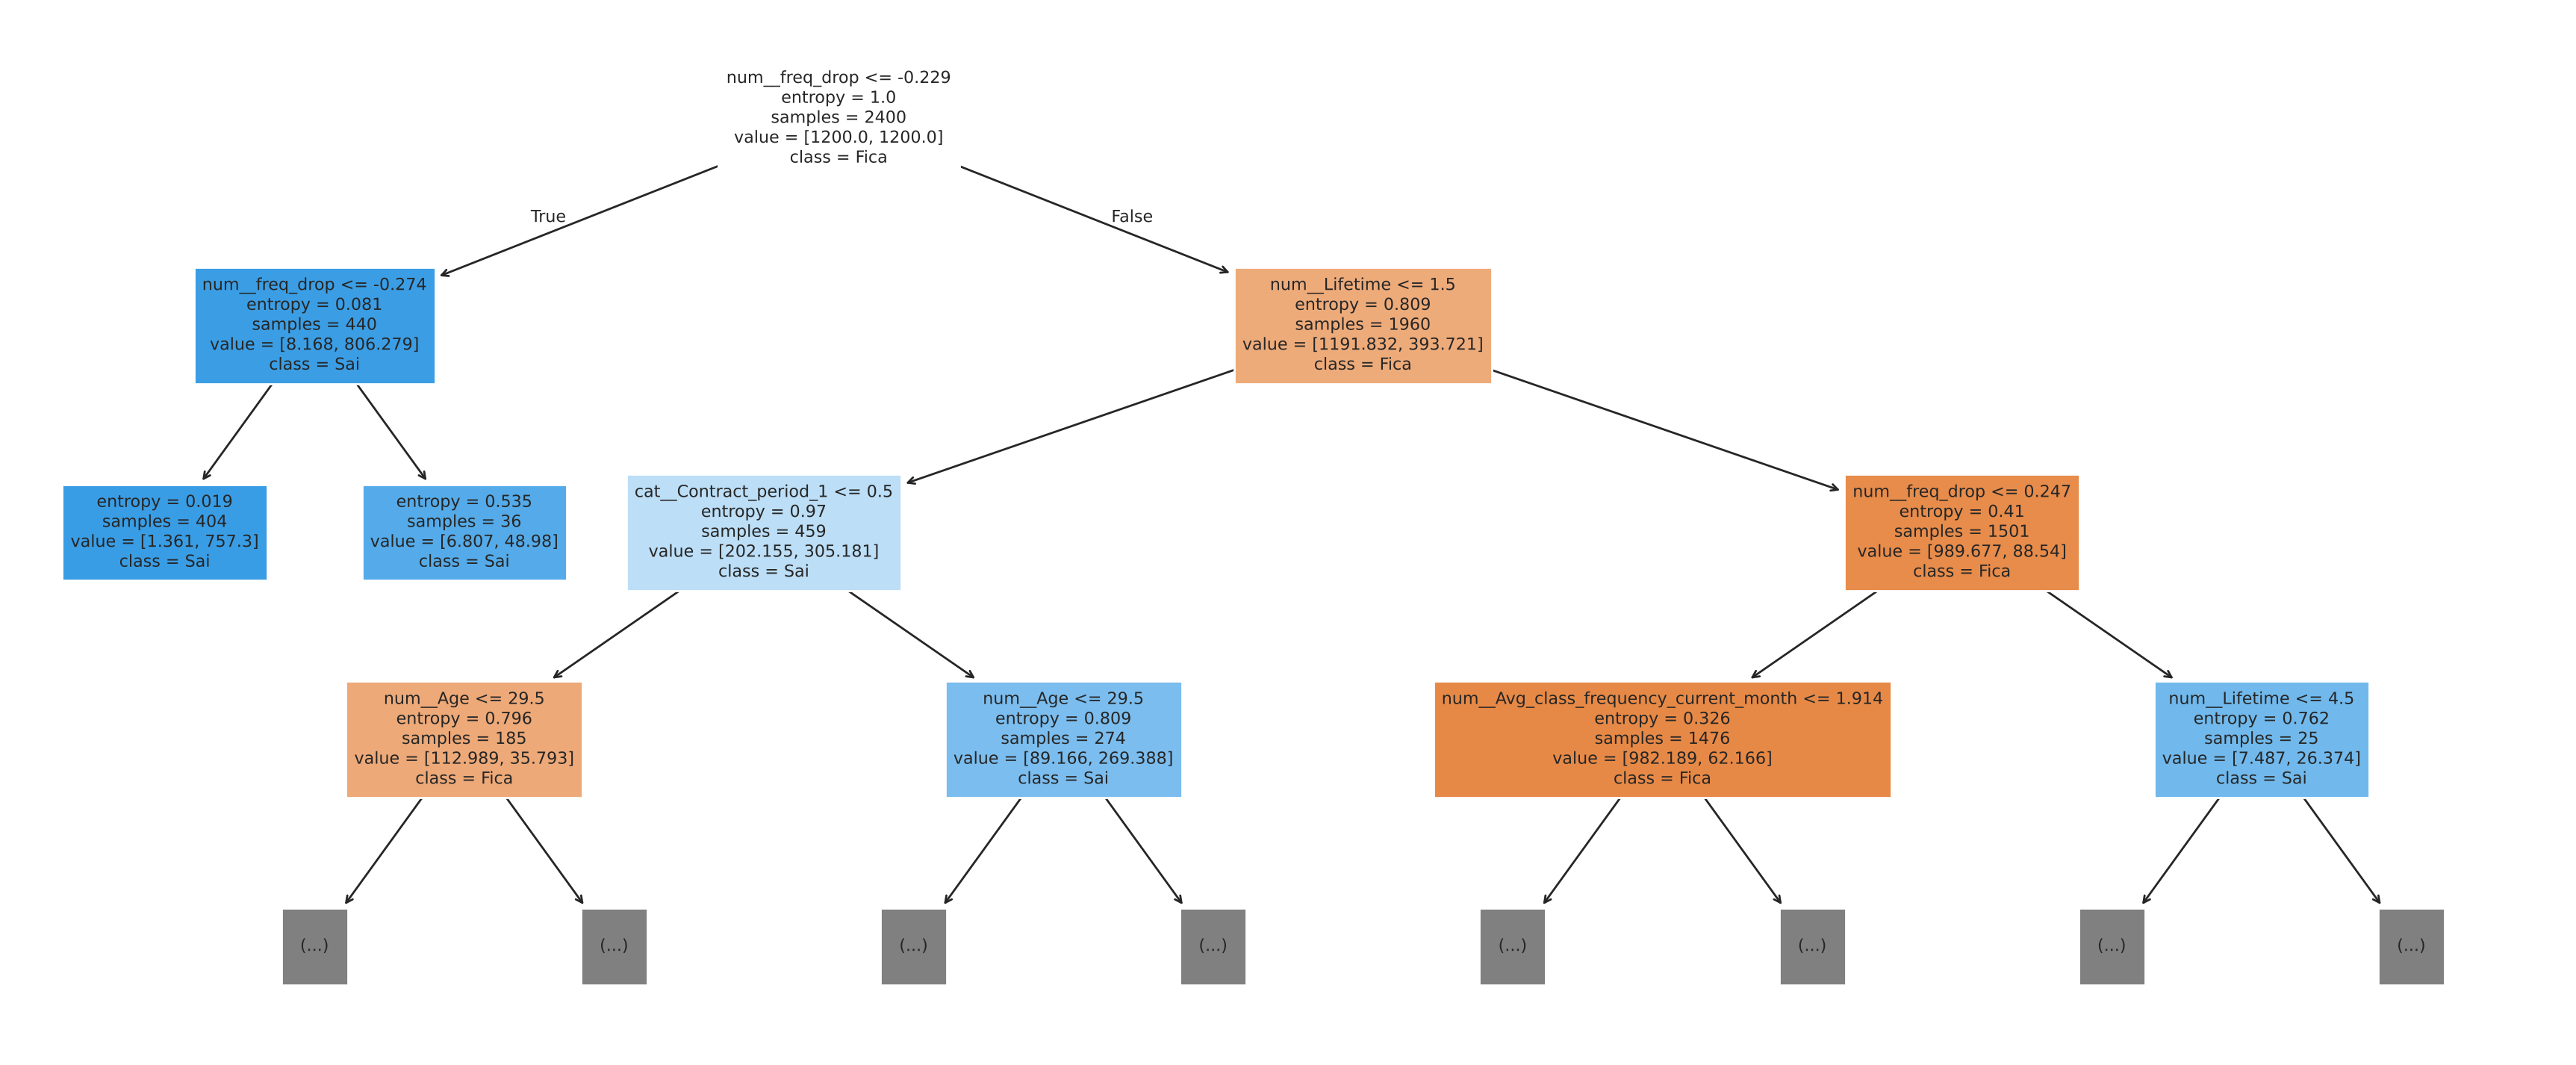

In [25]:
arv = modelos["Árvore de Decisão"]
prof = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(prep_arvore.fit_transform(X_train), y_train)
print("Árvore sem limite: profundidade", prof.get_depth(), "| F1 treino", round(f1_score(y_train, prof.predict(prep_arvore.transform(X_train))), 3),
      "| F1 val", round(f1_score(y_val, prof.predict(prep_arvore.transform(X_val))), 3))
plt.figure(figsize=(22, 9))
plot_tree(arv.named_steps["clf"], feature_names=arv.named_steps["prep"].get_feature_names_out(),
          class_names=["Fica", "Sai"], filled=True, max_depth=3, fontsize=8)
plt.show()

A árvore sem limite tem F1 = 1,0 no treino e cai na validação (**overfitting**). A árvore otimizada é rasa, generaliza melhor e pode ser lida como regras de negócio.

### 3.7 Ensembles
Modelos diferentes erram em pontos diferentes; combinando-os, erros independentes se compensam → menor variância (Bagging/RF) ou menor viés (Boosting).

#### Bagging e Random Forest
Cada árvore treina numa amostra **bootstrap** (sorteio com reposição): a chance de uma linha nunca ser sorteada é $(1-1/n)^n \to e^{-1} \approx 36,8\%$, logo ~63,2% aparecem. As linhas de fora (**out-of-bag**) servem de validação gratuita. A **Random Forest** sorteia **registros e atributos** (`max_features`), descorrelacionando as árvores.

In [26]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
treinar("Bagging (árvores)",
        Pipeline([("prep", prep_arvore), ("clf", BaggingClassifier(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                                                                 oob_score=True, random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [100, 300], "clf__max_samples": [0.6, 1.0]})
treinar("Random Forest",
        Pipeline([("prep", prep_arvore), ("clf", RandomForestClassifier(class_weight="balanced", oob_score=True, random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [200, 500], "clf__max_depth": [None, 8, 12], "clf__max_features": ["sqrt", 0.5],
         "clf__min_samples_leaf": [1, 3, 5]})
n = len(X_train); print(f"Fração teórica no bootstrap: {1 - (1 - 1/n)**n:.3f}")
print("OOB score Bagging:", round(modelos["Bagging (árvores)"].named_steps["clf"].oob_score_, 3),
      "| OOB score RF:", round(modelos["Random Forest"].named_steps["clf"].oob_score_, 3))

Bagging (árvores): {'clf__max_samples': 0.6, 'clf__n_estimators': 300} | F1 CV = 0.902 | F1 val = 0.916


Random Forest: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 500} | F1 CV = 0.909 | F1 val = 0.910
Fração teórica no bootstrap: 0.632
OOB score Bagging: 0.951 | OOB score RF: 0.954


#### Boosting — AdaBoost, Gradient Boosting e XGBoost
- **AdaBoost:** árvores rasas em sequência; cada nova árvore dá **mais peso aos exemplos errados** pela anterior.
- **Gradient Boosting:** cada nova árvore ajusta o **gradiente da função de perda** (log loss) dos erros anteriores; `learning_rate` controla o passo.
- **XGBoost:** Gradient Boosting com regularização L1/L2, paralelismo e tratamento eficiente — relação direta com o GB.
- **Early stopping:** interrompe quando a validação para de melhorar, evitando overfitting.

In [27]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
peso = (y_train == 0).sum() / (y_train == 1).sum()
treinar("AdaBoost",
        Pipeline([("prep", prep_arvore), ("clf", AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, class_weight="balanced"), random_state=SEED))]),
        {"clf__n_estimators": [100, 300], "clf__learning_rate": [0.1, 0.5, 1.0]})
treinar("Gradient Boosting",
        Pipeline([("prep", prep_arvore), ("clf", GradientBoostingClassifier(random_state=SEED, n_iter_no_change=10, validation_fraction=0.1))]),
        {"clf__n_estimators": [200, 500], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3, 4]})
treinar("XGBoost",
        Pipeline([("prep", prep_arvore), ("clf", XGBClassifier(scale_pos_weight=peso, eval_metric="logloss", random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [200, 400], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [3, 4, 6]});
print("Árvores usadas pelo GB (early stopping):", modelos["Gradient Boosting"].named_steps["clf"].n_estimators_)

AdaBoost: {'clf__learning_rate': 1.0, 'clf__n_estimators': 100} | F1 CV = 0.876 | F1 val = 0.868


Gradient Boosting: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 200} | F1 CV = 0.913 | F1 val = 0.921


XGBoost: {'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 400} | F1 CV = 0.913 | F1 val = 0.903
Árvores usadas pelo GB (early stopping): 179


**Obs.:** o Gradient Boosting do scikit-learn não tem `class_weight`; por isso seu Recall tende a ser menor no limiar 0,5. Isso é corrigido na seção 4 com o **ajuste de limiar**.

#### Voting e Stacking
- **Hard voting:** maioria dos votos. **Soft voting:** média das probabilidades (usa a confiança de cada modelo — geralmente melhor quando os modelos são calibrados).
- **Stacking:** um meta-modelo aprende a combinar as previsões dos modelos base. As previsões usadas para treinar o meta-modelo são **out-of-fold** (cada linha é prevista por modelos que não a viram), senão o meta-modelo aprenderia com previsões "viciadas" do treino.

In [28]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
base = [("lr", modelos["Regressão Logística"]), ("svm", modelos["SVM RBF"]),
        ("rf", modelos["Random Forest"]), ("xgb", modelos["XGBoost"])]
for nome, vot in [("Voting hard", "hard"), ("Voting soft", "soft")]:
    t = time.time()
    m = VotingClassifier(base, voting=vot, n_jobs=-1).fit(X_train, y_train)
    modelos[nome] = m; r = avaliar(nome, m, X_val, y_val) if vot == "soft" else {**avaliar(nome, m, X_val, y_val), "ROC_AUC": np.nan}
    r["tempo_s"] = time.time() - t; resultados.append(r)
t = time.time()
stk = StackingClassifier(base, final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000),
                         cv=cv, stack_method="predict_proba", n_jobs=-1).fit(X_train, y_train)
modelos["Stacking"] = stk; r = avaliar("Stacking", stk, X_val, y_val); r["tempo_s"] = time.time() - t; resultados.append(r)
print("Pesos do meta-modelo:", dict(zip([b[0] for b in base], stk.final_estimator_.coef_[0].round(2))))

Pesos do meta-modelo: {'lr': np.float64(1.58), 'svm': np.float64(1.83), 'rf': np.float64(3.11), 'xgb': np.float64(2.49)}


### 3.8 Comparação na validação (limiar padrão 0,5)

In [29]:
res_val = pd.DataFrame(resultados).set_index("modelo")[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "F1_CV", "tempo_s"]]
res_val.sort_values("F1", ascending=False).round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC,F1_CV,tempo_s
modelo,,,,,,,
Gradient Boosting,0.959,0.932,0.910,0.921,0.989,0.913,8.677
Bagging (árvores),0.956,0.932,0.901,0.916,0.986,0.902,10.000
Voting hard,0.952,0.907,0.915,0.911,NaN,NaN,1.516
Random Forest,0.951,0.895,0.925,0.910,0.986,0.909,86.584
Voting soft,0.950,0.884,0.934,0.908,0.989,NaN,1.293
XGBoost,0.948,0.886,0.920,0.903,0.987,0.913,2.998
Stacking,0.945,0.862,0.943,0.901,0.988,NaN,6.513
Árvore de Decisão,0.936,0.855,0.915,0.884,0.967,0.876,6.453
SVM RBF,0.926,0.815,0.934,0.870,0.987,0.888,12.185


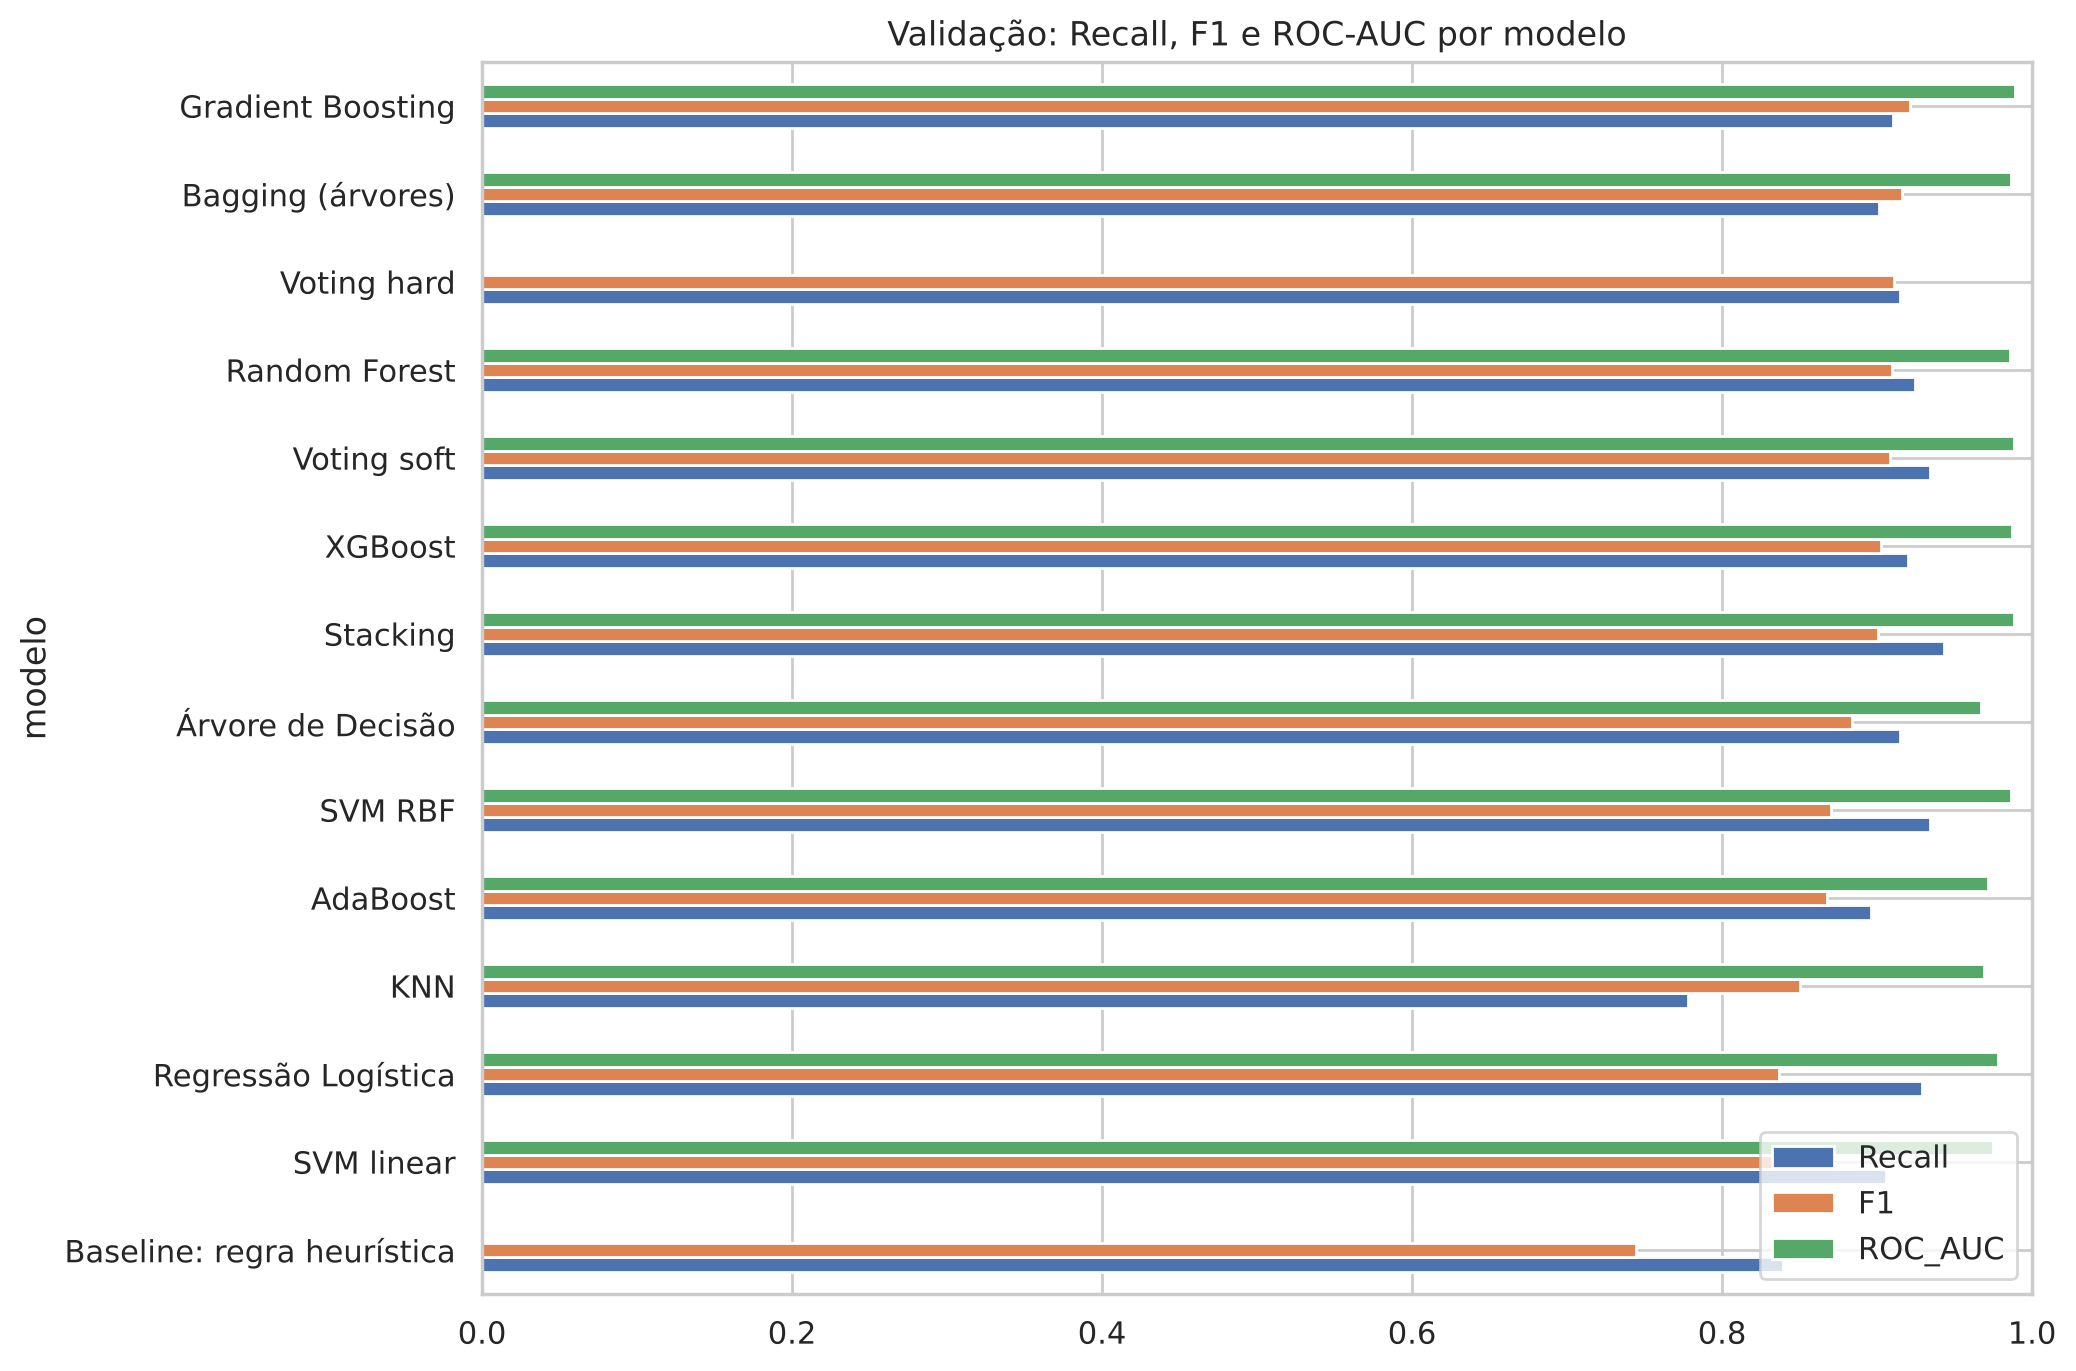

In [30]:
ax = res_val.drop(index=["Baseline: sempre 0"])[["Recall", "F1", "ROC_AUC"]].sort_values("F1").plot.barh(figsize=(10, 8))
ax.set_xlim(0, 1); ax.set_title("Validação: Recall, F1 e ROC-AUC por modelo"); plt.show()

## 4. Avaliação e análise de resultados
### 4.1 Ajuste do limiar de decisão
Reduzir τ faz o modelo acusar "sai" com mais facilidade: **Recall sobe, Precision cai** (mais falsos positivos). Critério de negócio: exigir **Recall ≥ 0,90** e, entre os limiares que cumprem isso, escolher o de **maior F1**. O limiar é escolhido **na validação** — nunca no teste.

In [31]:
from sklearn.metrics import precision_recall_curve, roc_curve, log_loss, brier_score_loss
from sklearn.calibration import calibration_curve

def escolher_limiar(y_, p_, recall_min=0.90):
    taus = np.round(np.arange(0.05, 0.96, 0.01), 2)
    tab = pd.DataFrame([{"tau": t, "Recall": recall_score(y_, p_ >= t),
                         "Precision": precision_score(y_, p_ >= t, zero_division=0),
                         "F1": f1_score(y_, p_ >= t)} for t in taus])
    ok = tab[tab["Recall"] >= recall_min]
    return (ok.loc[ok["F1"].idxmax(), "tau"] if len(ok) else 0.5), tab

com_proba = [m for m in modelos if hasattr(modelos[m], "predict_proba") and m != "Voting hard"]
limiares, curvas = {}, {}
for m in com_proba:
    limiares[m], curvas[m] = escolher_limiar(y_val, modelos[m].predict_proba(X_val)[:, 1])
pd.Series(limiares, name="tau_escolhido").sort_values()

KNN                    0.30
Árvore de Decisão      0.31
SVM linear             0.35
AdaBoost               0.46
Bagging (árvores)      0.48
SVM RBF                0.51
Gradient Boosting      0.53
XGBoost                0.55
Random Forest          0.56
Voting soft            0.59
Regressão Logística    0.62
Stacking               0.79
Name: tau_escolhido, dtype: float64

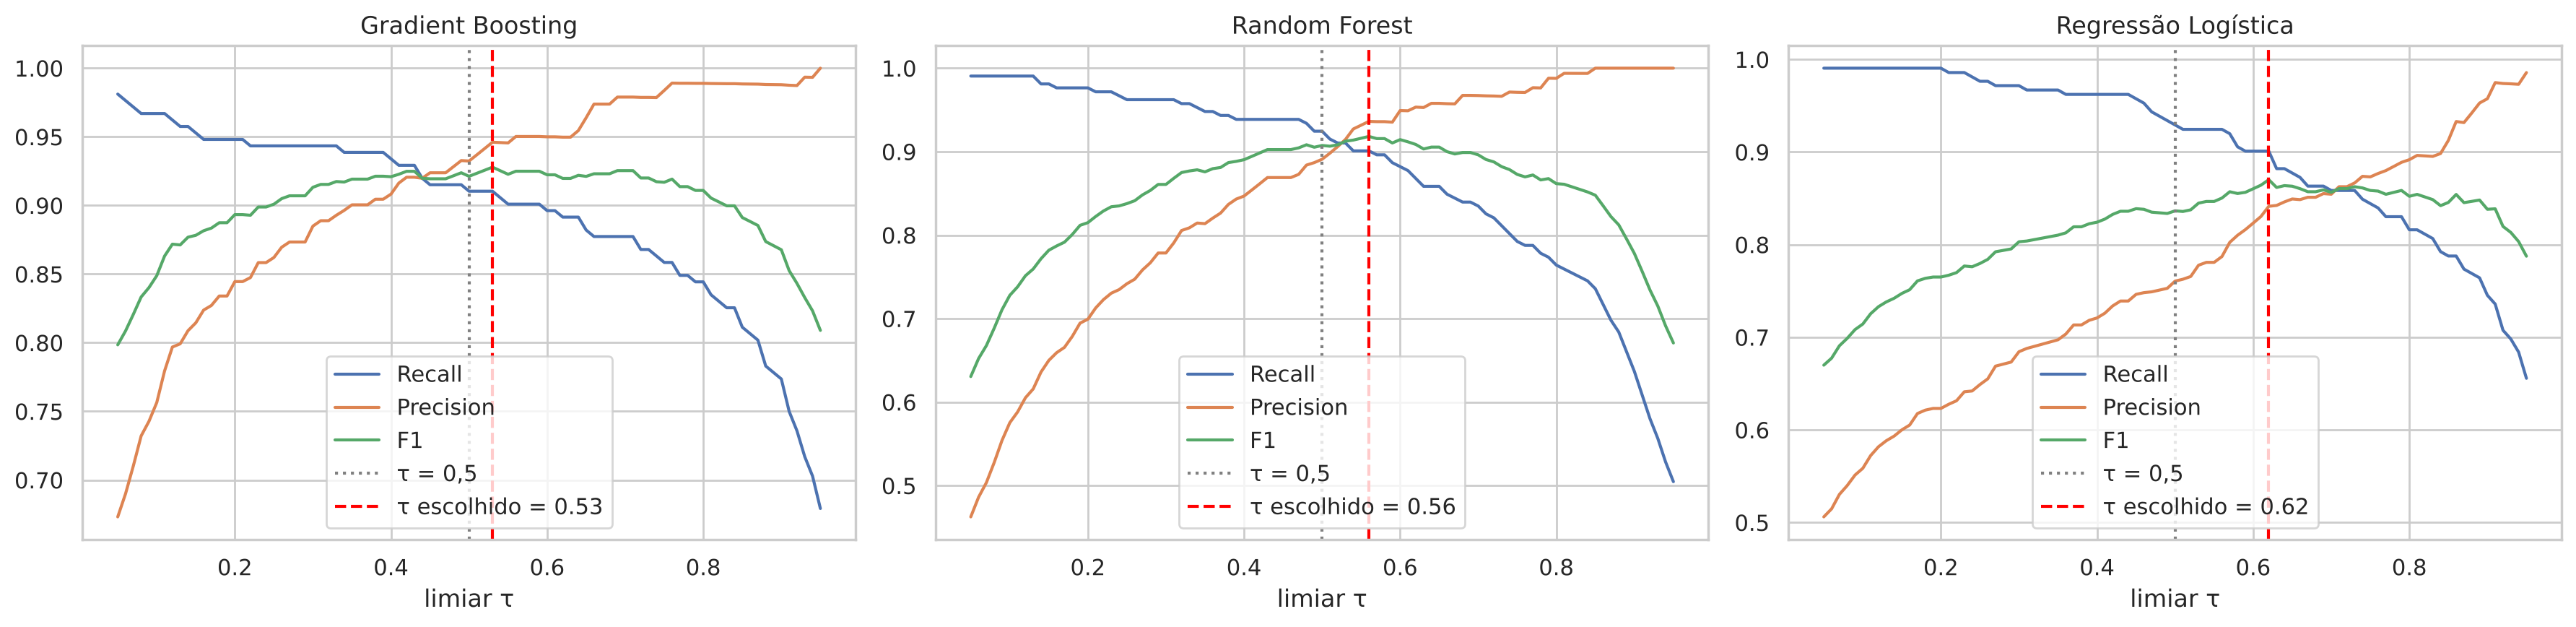

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, m in zip(ax, ["Gradient Boosting", "Random Forest", "Regressão Logística"]):
    t = curvas[m]
    a.plot(t["tau"], t["Recall"], label="Recall"); a.plot(t["tau"], t["Precision"], label="Precision"); a.plot(t["tau"], t["F1"], label="F1")
    a.axvline(0.5, ls=":", c="gray", label="τ = 0,5"); a.axvline(limiares[m], ls="--", c="red", label=f"τ escolhido = {limiares[m]}")
    a.set_title(m); a.set_xlabel("limiar τ"); a.legend()
plt.tight_layout(); plt.show()

### 4.2 Resultado final no conjunto de teste
Avaliação **única** no teste, com o limiar padrão (0,5) e com o limiar escolhido na validação.

In [33]:
def metricas(nome, y_, pred, proba):
    return {"modelo": nome, "Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred),
            "ROC_AUC": roc_auc_score(y_, proba) if proba is not None else np.nan,
            "LogLoss": log_loss(y_, proba) if proba is not None else np.nan}

linhas = [metricas("Baseline: sempre 0", y_test, dummy.predict(X_test), np.full(len(y_test), y_train.mean())),
          metricas("Baseline: regra heurística", y_test, Heuristica().predict(X_test), None),
          {**metricas("Voting hard", y_test, modelos["Voting hard"].predict(X_test), None), "tau": 0.5}]
proba_test = {}
for m in com_proba:
    p = modelos[m].predict_proba(X_test)[:, 1]; proba_test[m] = p
    linhas.append({**metricas(m, y_test, (p >= 0.5).astype(int), p), "tau": 0.5})
    linhas.append({**metricas(m + " (τ ajustado)", y_test, (p >= limiares[m]).astype(int), p), "tau": limiares[m]})
res_test = pd.DataFrame(linhas).set_index("modelo")
res_test.sort_values("F1", ascending=False).round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss,tau
modelo,,,,,,,
Gradient Boosting,0.964,0.951,0.910,0.930,0.988,0.104,0.50
Gradient Boosting (τ ajustado),0.964,0.964,0.896,0.929,0.988,0.104,0.53
XGBoost (τ ajustado),0.961,0.925,0.929,0.927,0.988,0.121,0.55
Voting soft (τ ajustado),0.961,0.937,0.915,0.926,0.989,0.123,0.59
Stacking (τ ajustado),0.960,0.937,0.910,0.923,0.989,0.135,0.79
Bagging (árvores),0.959,0.950,0.892,0.920,0.984,0.162,0.50
Voting hard,0.958,0.924,0.915,0.919,NaN,NaN,0.50
XGBoost,0.956,0.908,0.929,0.918,0.988,0.121,0.50
Bagging (árvores) (τ ajustado),0.958,0.945,0.892,0.917,0.984,0.162,0.48


In [34]:
tab_aj = res_test[res_test.index.str.contains("ajustado")].sort_values("F1", ascending=False)
tab_aj.round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC,LogLoss,tau
modelo,,,,,,,
Gradient Boosting (τ ajustado),0.964,0.964,0.896,0.929,0.988,0.104,0.53
XGBoost (τ ajustado),0.961,0.925,0.929,0.927,0.988,0.121,0.55
Voting soft (τ ajustado),0.961,0.937,0.915,0.926,0.989,0.123,0.59
Stacking (τ ajustado),0.960,0.937,0.910,0.923,0.989,0.135,0.79
Bagging (árvores) (τ ajustado),0.958,0.945,0.892,0.917,0.984,0.162,0.48
SVM RBF (τ ajustado),0.956,0.932,0.901,0.916,0.985,0.126,0.51
Random Forest (τ ajustado),0.954,0.927,0.896,0.911,0.986,0.137,0.56
Árvore de Decisão (τ ajustado),0.941,0.863,0.925,0.893,0.966,0.270,0.31
AdaBoost (τ ajustado),0.934,0.860,0.896,0.878,0.977,0.358,0.46


### 4.3 Justificativa das métricas
- **Recall (principal):** "encontrei os clientes que iam sair?" Cada FN = mensalidades perdidas sem chance de reação.
- **Precision:** "quando o sistema alerta, posso confiar?" Cada FP = custo de uma ação de retenção (ligação, desconto) num cliente que ficaria. Barato, mas não pode explodir.
- **F1:** equilíbrio entre os dois (média harmônica $2PR/(P+R)$).
- **ROC-AUC:** capacidade de **ordenar** (quem sai recebe probabilidade maior que quem fica?) — independente do limiar. **AUC = 0,98 não significa 98% de acertos.**
- **Accuracy:** reportada, mas enganosa: o "sempre 0" já faz ~73,5%.
- **Log loss:** quanta probabilidade o modelo deu ao que realmente aconteceu — penaliza confiança errada.

### 4.4 Matrizes de confusão

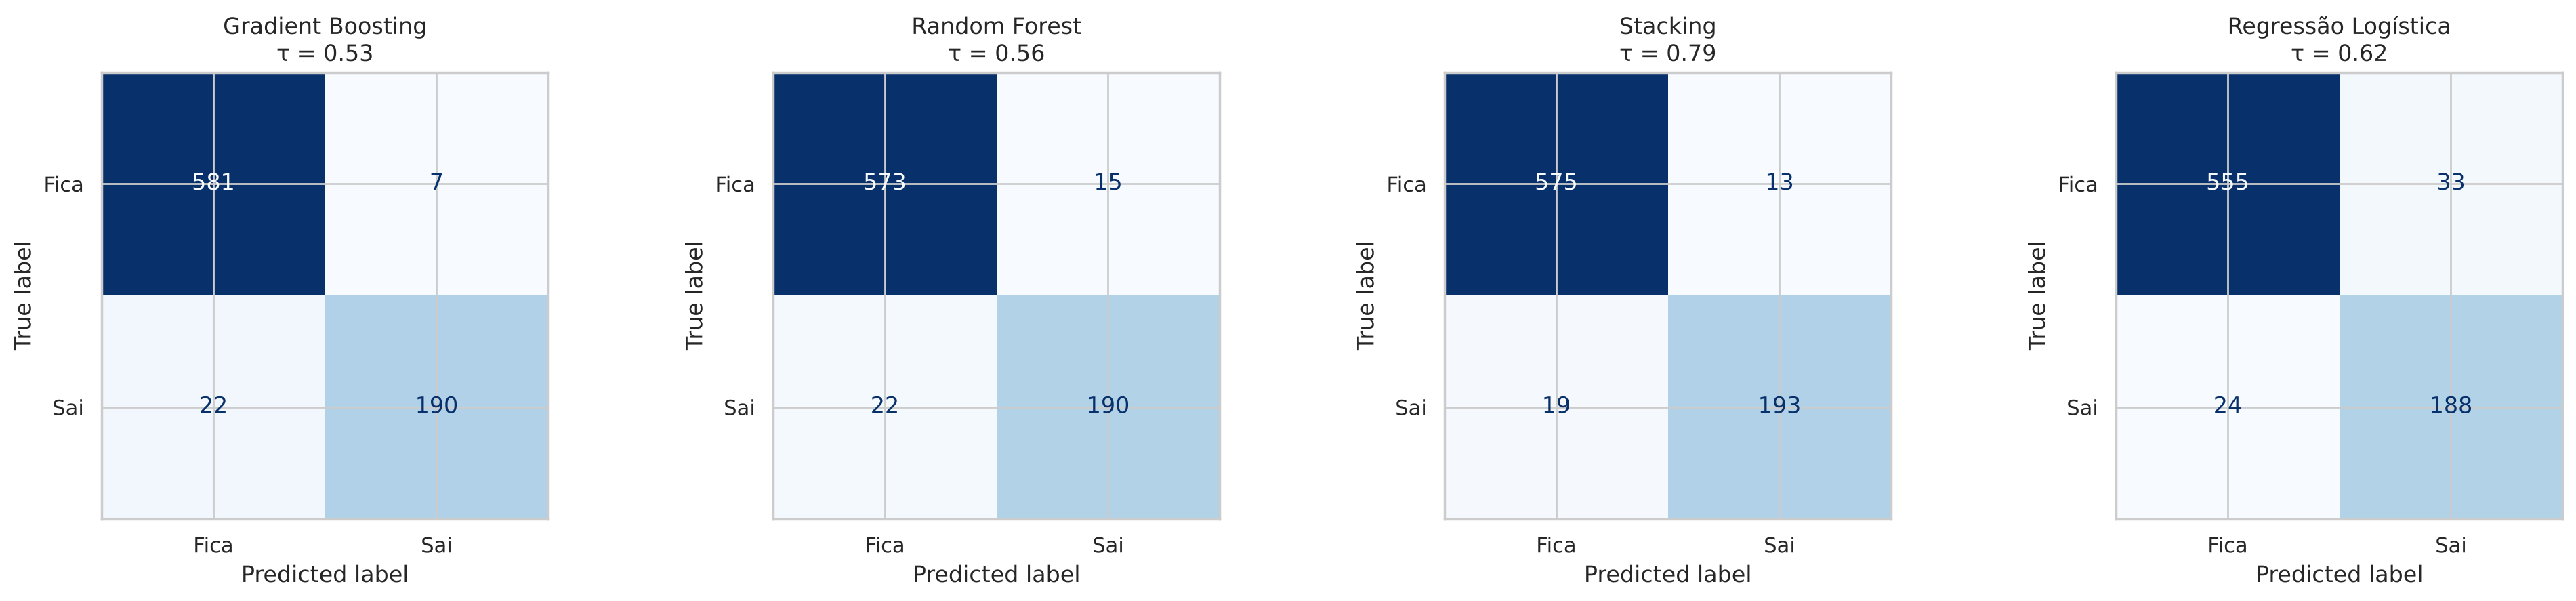

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay
sel = ["Gradient Boosting", "Random Forest", "Stacking", "Regressão Logística"]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, m in zip(ax, sel):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test[m] >= limiares[m]).astype(int),
                                            display_labels=["Fica", "Sai"], ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{m}\nτ = {limiares[m]}")
plt.tight_layout(); plt.show()

- **TP:** previu que sai e saiu → retenção bem direcionada.
- **TN:** previu que fica e ficou.
- **FP:** previu que sai, mas ficaria → ação de retenção "desperdiçada" (custo baixo).
- **FN:** previu que fica, mas saiu → **cliente perdido sem reação** (erro crítico).

### 4.5 Curvas ROC

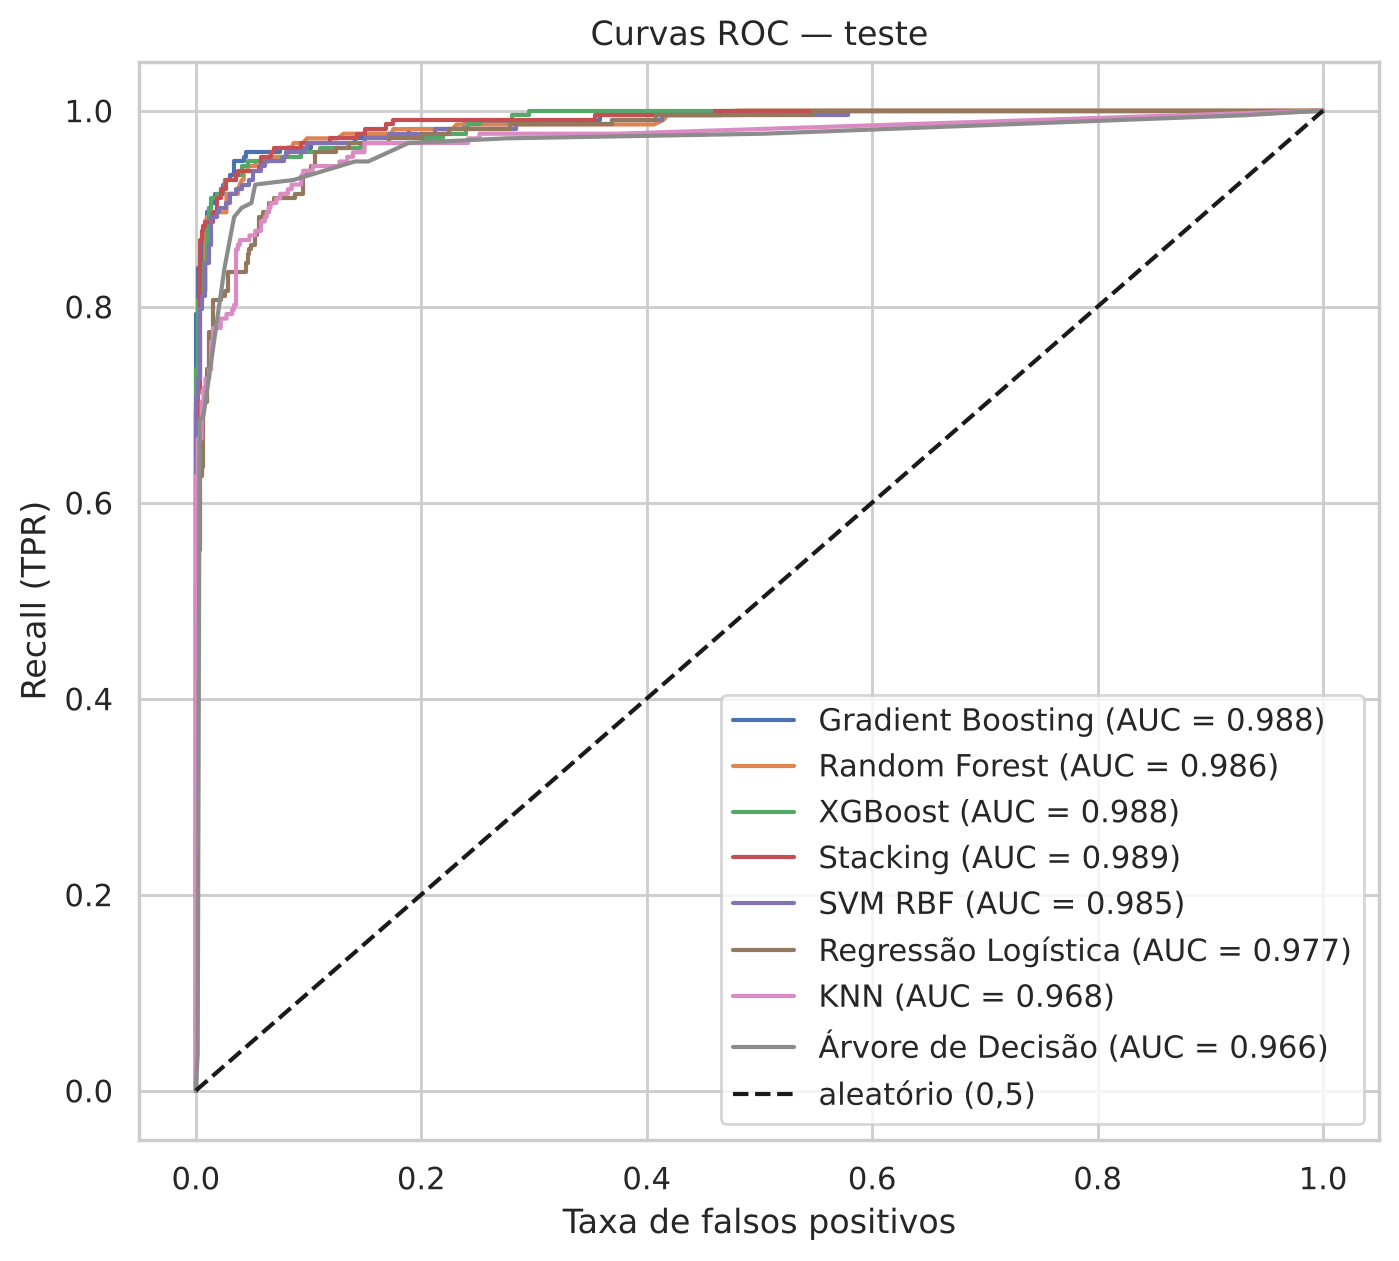

In [36]:
plt.figure(figsize=(8, 7))
for m in ["Gradient Boosting", "Random Forest", "XGBoost", "Stacking", "SVM RBF", "Regressão Logística", "KNN", "Árvore de Decisão"]:
    fpr, tpr, _ = roc_curve(y_test, proba_test[m])
    plt.plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_test, proba_test[m]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="aleatório (0,5)")
plt.xlabel("Taxa de falsos positivos"); plt.ylabel("Recall (TPR)"); plt.title("Curvas ROC — teste"); plt.legend(); plt.show()

A AUC é a probabilidade de um cliente que **sai**, sorteado ao acaso, receber probabilidade **maior** que um cliente que **fica**. Mede ordenação, não acerto.

### 4.6 Calibração das probabilidades

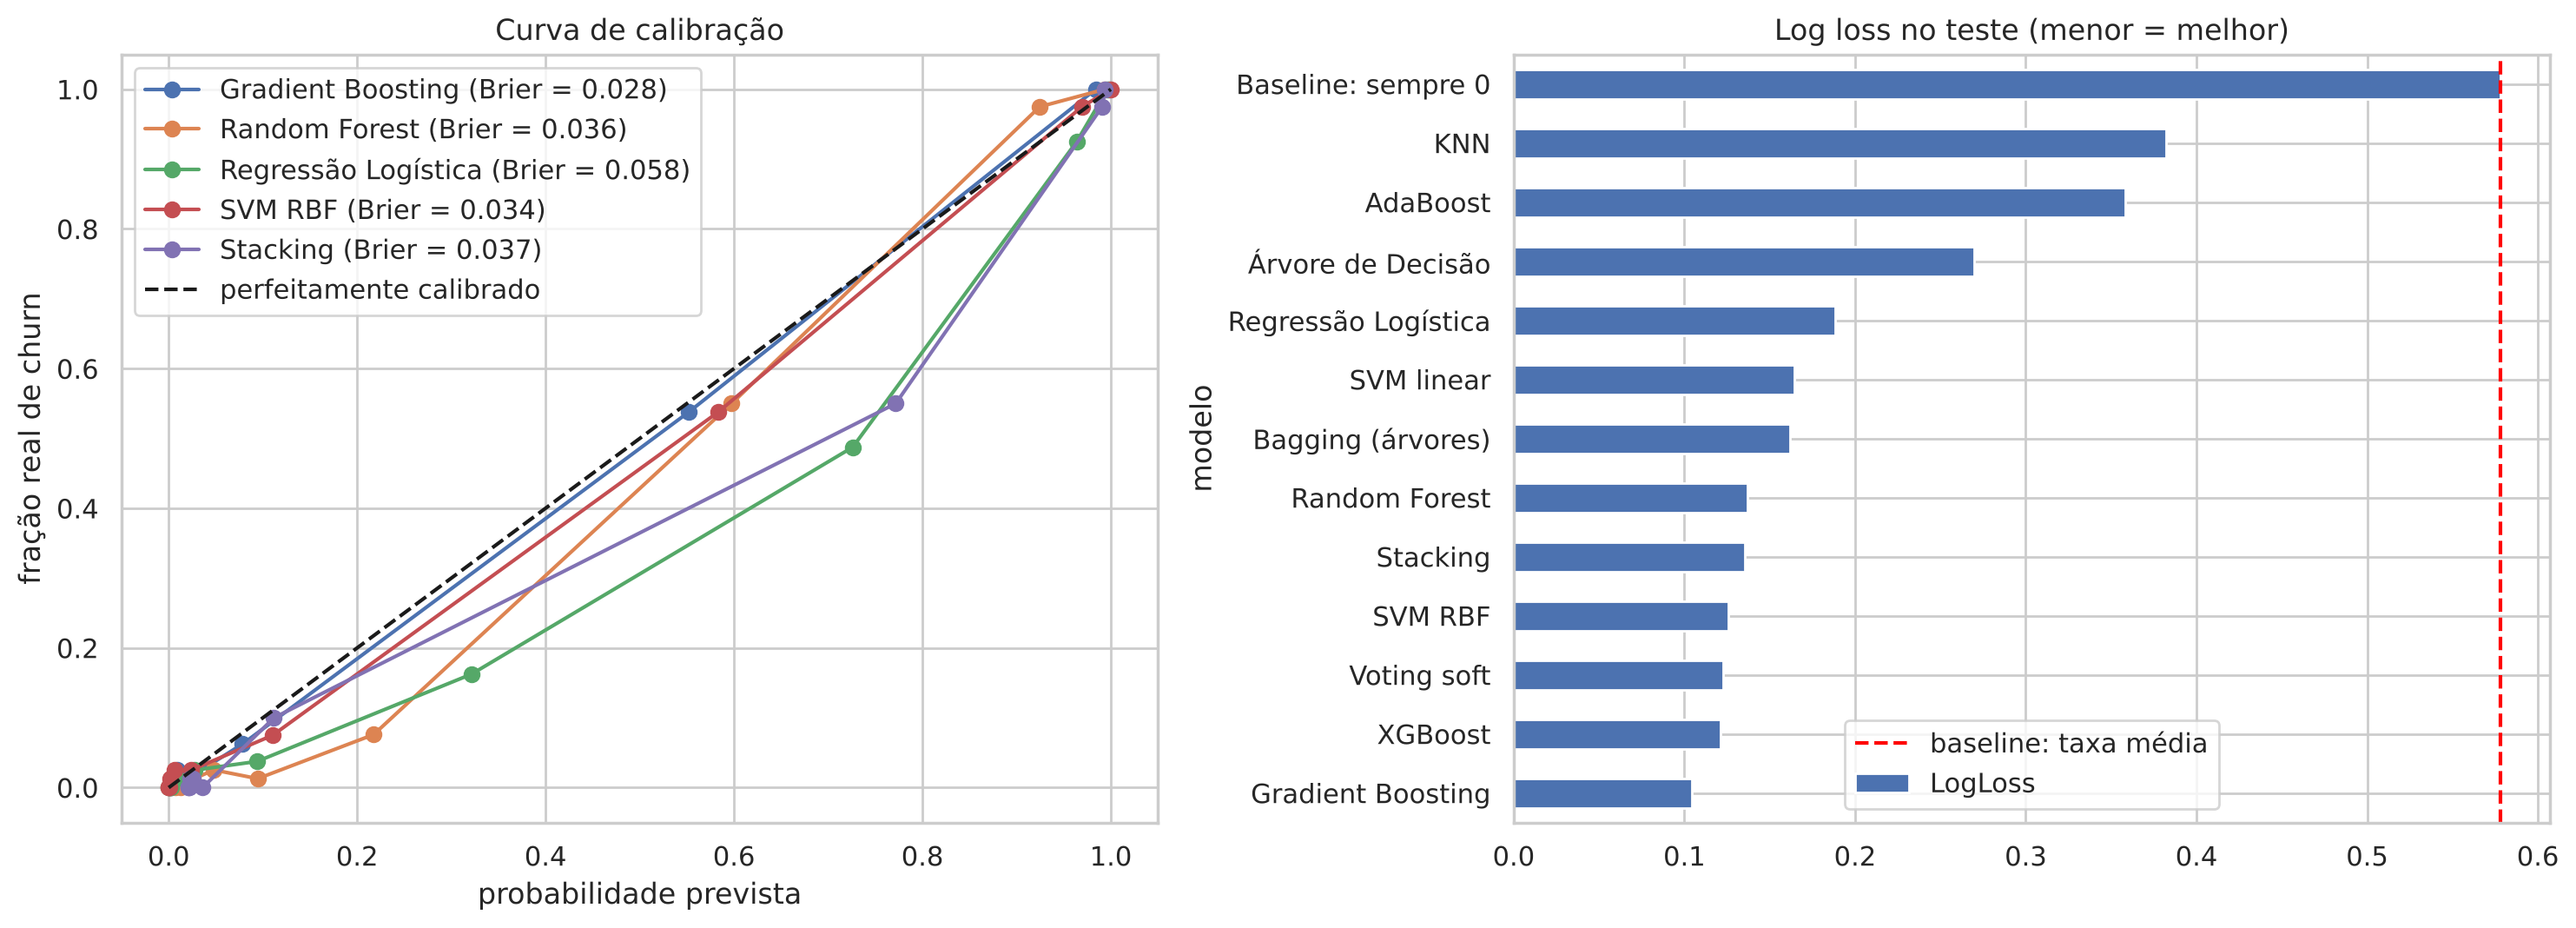

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for m in ["Gradient Boosting", "Random Forest", "Regressão Logística", "SVM RBF", "Stacking"]:
    fr, mp = calibration_curve(y_test, proba_test[m], n_bins=10, strategy="quantile")
    ax[0].plot(mp, fr, marker="o", label=f"{m} (Brier = {brier_score_loss(y_test, proba_test[m]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="perfeitamente calibrado")
ax[0].set_xlabel("probabilidade prevista"); ax[0].set_ylabel("fração real de churn"); ax[0].legend(); ax[0].set_title("Curva de calibração")
res_test[~res_test.index.str.contains("ajustado")]["LogLoss"].dropna().sort_values().plot.barh(ax=ax[1])
ax[1].axvline(log_loss(y_test, np.full(len(y_test), y_train.mean())), ls="--", c="red", label="baseline: taxa média")
ax[1].set_title("Log loss no teste (menor = melhor)"); ax[1].legend()
plt.tight_layout(); plt.show()

Num modelo calibrado, entre os clientes com p ≈ 0,70, cerca de 70% realmente saem. Modelos treinados com `class_weight='balanced'` tendem a superestimar a probabilidade de churn (a curva fica abaixo da diagonal) — boa ordenação (AUC) não implica probabilidade calibrada; compare as curvas e o Brier score. O log loss de cada modelo é comparado com o baseline que sempre prevê a taxa média de churn.

### 4.7 Análise de erros

In [38]:
melhor = tab_aj.index[0].replace(" (τ ajustado)", "")
p = proba_test[melhor]; pred = (p >= limiares[melhor]).astype(int)
err = X_test.assign(Churn=y_test.values, proba=p.round(3), pred=pred)
err["tipo"] = np.select([(err.Churn == 1) & (err.pred == 0), (err.Churn == 0) & (err.pred == 1)], ["FN", "FP"], "acerto")
print("Melhor modelo:", melhor, "| τ =", limiares[melhor])
print(err["tipo"].value_counts())
err.groupby("tipo")[["Lifetime", "Contract_period", "Avg_class_frequency_current_month", "freq_drop", "Age", "proba"]].median().round(2)

Melhor modelo: Gradient Boosting | τ = 0.53
tipo
acerto    771
FN         22
FP          7
Name: count, dtype: int64


,Lifetime,Contract_period,Avg_class_frequency_current_month,freq_drop,Age,proba
tipo,,,,,,
FN,1.0,1.0,1.40,-0.03,30.5,0.30
FP,0.0,1.0,2.08,-0.08,28.0,0.75
acerto,3.0,6.0,1.67,-0.03,29.0,0.01


In [39]:
err[err.tipo == "FN"].sort_values("proba").head(10)

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Lifetime,Avg_class_frequency_current_month,freq_drop,contrato_restante_pct,Churn,proba,pred,tipo
1517,0,1,1,1,1,1,0,34,280.189493,2,2.724581,-0.068599,1.000000,1,0.006,0,FN
1952,0,1,0,0,1,6,0,31,46.971990,2,1.312806,0.058262,0.666667,1,0.011,0,FN
876,0,1,1,1,1,6,0,31,248.356955,1,2.051480,-0.073578,1.000000,1,0.011,0,FN
3262,0,1,0,0,0,1,0,27,130.144131,2,3.141712,-0.032606,1.000000,1,0.021,0,FN
577,0,1,0,0,1,1,0,32,49.628121,1,2.549752,0.086216,1.000000,1,0.034,0,FN
3854,0,1,0,0,1,1,0,25,100.806471,3,2.532091,-0.149344,1.000000,1,0.048,0,FN
1951,0,1,1,0,1,1,0,33,161.661181,4,2.479798,-0.233009,1.000000,1,0.056,0,FN
3096,0,1,0,0,1,1,0,31,133.209579,3,0.000000,0.000000,1.000000,1,0.099,0,FN
3705,0,1,0,0,1,1,0,29,60.885977,5,0.000000,0.000000,1.000000,1,0.141,0,FN
1224,1,1,0,0,1,1,1,31,281.634345,0,2.184527,-0.099733,1.000000,1,0.259,0,FN


**Leitura (22 FN, 7 FP em 800):** os FN são clientes novos (Lifetime ≈ 1) com contrato de 1 mês — o perfil de risco —, mas com **frequência relativamente alta e sem queda recente** (`freq_drop` ≈ 0). O modelo confiou no engajamento e eles saíram mesmo assim, provavelmente por motivos **ausentes nos dados** (preço, mudança, saúde). Os FP são clientes recém-chegados (Lifetime ≈ 0) que receberam probabilidade alta e ficaram. O erro crítico (FN) é controlado, mas não eliminado: com τ escolhido na validação, o Recall no teste ficou em 0,896, levemente abaixo da meta de 0,90 — efeito esperado de amostra.

## 5. Importância dos atributos
Três visões diferentes, que respondem perguntas diferentes:
1. **Coeficientes da Logística:** direção e tamanho do efeito (por desvio padrão), assumindo relação linear no log-odds.
2. **Importância por impureza (RF):** quanto cada atributo reduziu a impureza nas árvores — enviesada para variáveis contínuas com muitos valores.
3. **Permutation importance (teste):** quanto o F1 **cai** ao embaralhar o atributo — a mais honesta, mede dependência real do modelo.

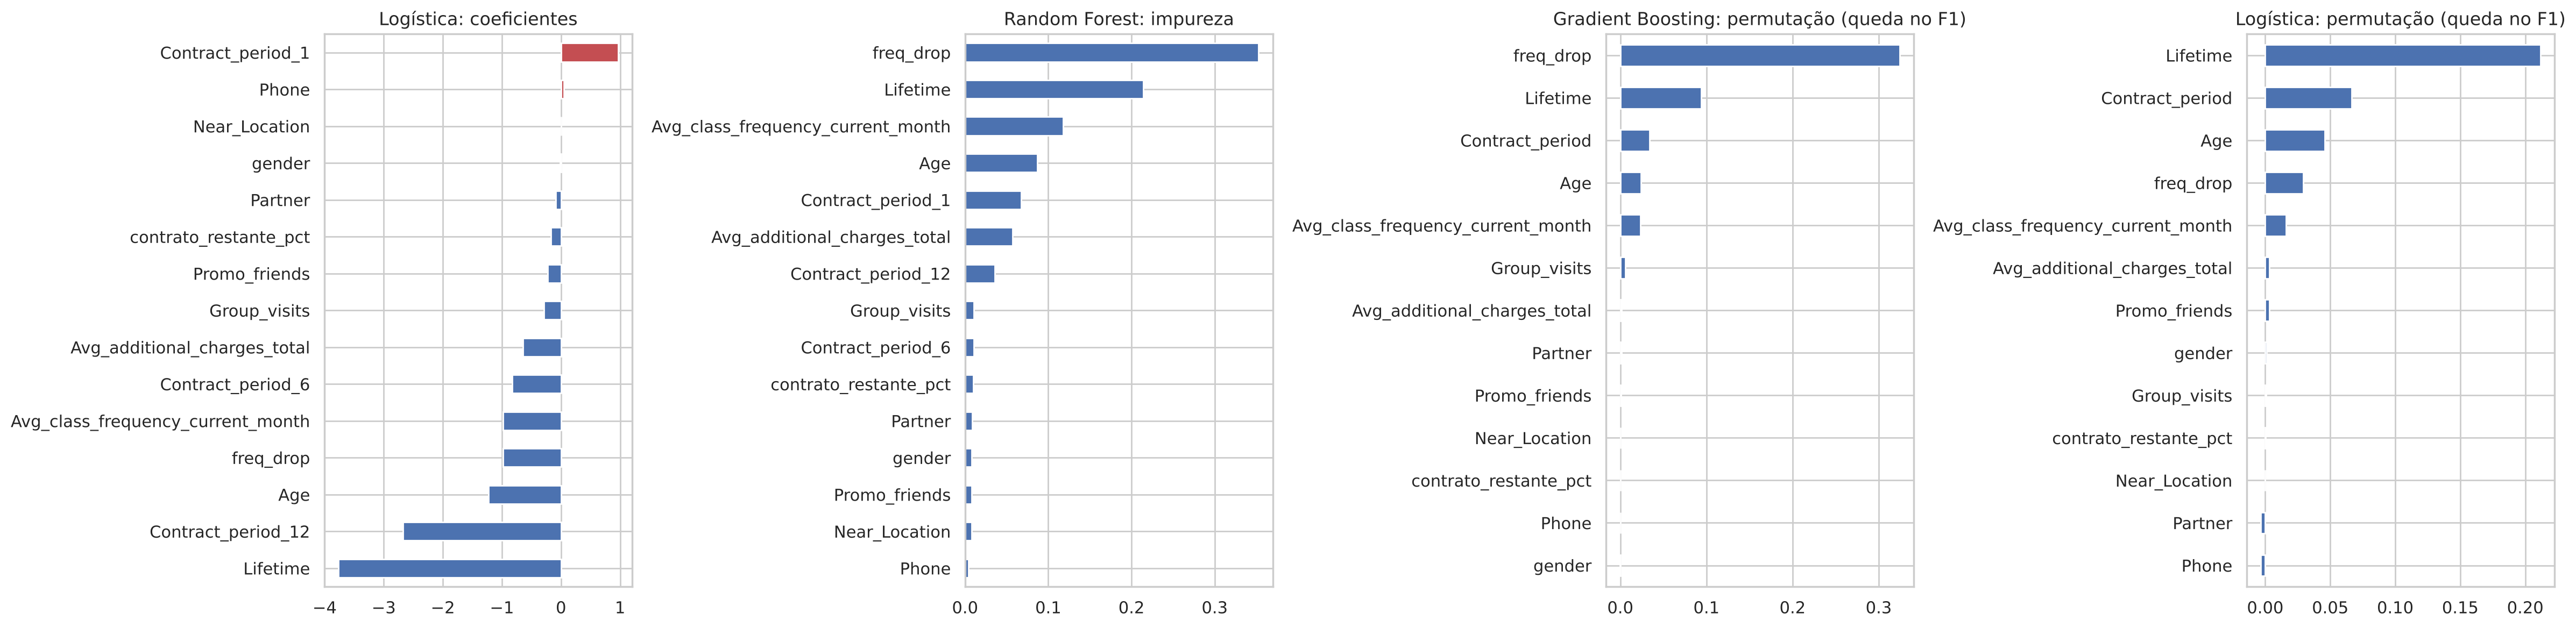

,perm_Gradient Boosting,perm_Logística
freq_drop,0.3244,0.0294
Lifetime,0.0938,0.2117
Contract_period,0.0342,0.0666
Age,0.0237,0.0458
Avg_class_frequency_current_month,0.0235,0.0162
Group_visits,0.0056,0.0007
Avg_additional_charges_total,0.0017,0.0031
Partner,0.0013,-0.0034
Promo_friends,0.0010,0.0030
Near_Location,0.0004,0.0000


In [40]:
from sklearn.inspection import permutation_importance
rf = modelos["Random Forest"]
imp_rf = pd.Series(rf.named_steps["clf"].feature_importances_, index=rf.named_steps["prep"].get_feature_names_out())
imp_rf.index = imp_rf.index.str.replace("num__", "").str.replace("cat__", "")
perm = {}
for m in [melhor, "Regressão Logística"]:
    r = permutation_importance(modelos[m], X_test, y_test, scoring="f1", n_repeats=20, random_state=SEED, n_jobs=-1)
    perm[m] = pd.Series(r.importances_mean, index=X_test.columns)
coef_lr = coef.copy(); coef_lr.index = coef_lr.index.str.replace("num__", "").str.replace("cat__", "")

fig, ax = plt.subplots(1, 4, figsize=(24, 6))
coef_lr.sort_values().plot.barh(ax=ax[0], color=np.where(coef_lr.sort_values() < 0, "#4C72B0", "#C44E52")); ax[0].set_title("Logística: coeficientes")
imp_rf.sort_values().plot.barh(ax=ax[1]); ax[1].set_title("Random Forest: impureza")
perm[melhor].sort_values().plot.barh(ax=ax[2]); ax[2].set_title(f"{melhor}: permutação (queda no F1)")
perm["Regressão Logística"].sort_values().plot.barh(ax=ax[3]); ax[3].set_title("Logística: permutação (queda no F1)")
plt.tight_layout(); plt.show()
pd.DataFrame({f"perm_{melhor}": perm[melhor], "perm_Logística": perm["Regressão Logística"]}).sort_values(f"perm_{melhor}", ascending=False).round(4)

As visões concordam no grupo do topo — **`freq_drop`, `Lifetime`, tipo de contrato, idade e frequência no mês atual** —, mas discordam na ordem, e isso responde "importante para qual modelo?":
- No **Gradient Boosting**, a feature criada **`freq_drop` é a mais importante** (embaralhá-la derruba o F1 em 0,32): o modelo não-linear aproveita a **queda recente de frequência** como sinal de abandono.
- Na **Logística**, `Lifetime` domina (0,21); `freq_drop` pesa pouco porque o efeito dela não é linear.
- `gender`, `Phone`, `Near_Location` e `contrato_restante_pct` ≈ 0 → poderiam ser removidas sem perda (a feature criada `contrato_restante_pct` não funcionou: 55% dos clientes têm contrato de 1 mês, onde ela vale sempre 1).
- **Importância não é causa:** "Lifetime importa" não significa que aumentar o tempo de casa por si só evita o abandono.

## 6. Análise crítica: desempenho × interpretabilidade

In [41]:
resumo = pd.concat([res_test.loc[["Baseline: sempre 0", "Baseline: regra heurística"]],
                    tab_aj.loc[[melhor + " (τ ajustado)", "Random Forest (τ ajustado)", "Árvore de Decisão (τ ajustado)", "Regressão Logística (τ ajustado)"]]])
resumo[["tau", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]].round(3)

,tau,Accuracy,Precision,Recall,F1,ROC_AUC
modelo,,,,,,
Baseline: sempre 0,NaN,0.735,0.000,0.000,0.000,0.500
Baseline: regra heurística,NaN,0.845,0.676,0.797,0.732,NaN
Gradient Boosting (τ ajustado),0.53,0.964,0.964,0.896,0.929,0.988
Random Forest (τ ajustado),0.56,0.954,0.927,0.896,0.911,0.986
Árvore de Decisão (τ ajustado),0.31,0.941,0.863,0.925,0.893,0.966
Regressão Logística (τ ajustado),0.62,0.929,0.851,0.887,0.868,0.977


- **Melhor desempenho:** ensemble de árvores com limiar ajustado — supera a regra heurística com folga em F1 e Precision mantendo Recall ≥ 0,90.
- **Interpretabilidade:** a **Árvore de Decisão** rasa e a **Regressão Logística** ficam alguns pontos abaixo, mas suas regras/coeficientes podem ser explicados diretamente à gestão da academia.
- **Compensação:** para **priorizar a lista de contatos de retenção**, o ensemble é o mais indicado; para **explicar os fatores** do abandono, a Logística/Árvore complementam.
- **Limitações:** dataset de uma única rede, sem datas (não testamos estabilidade no tempo); ausência de motivos externos explica parte dos FN.

## 7. Segmentação de clientes com K-Means (aprendizagem não supervisionada)
### 7.1 Objetivo da segmentação
- **Pergunta:** quais **perfis de engajamento** existem entre os clientes da academia?
- **Unidade de análise:** um cliente (uma linha).
- **Explorar, não reconhecer:** o `Churn` **não entra** no agrupamento. Ele só é usado **depois**, como evidência externa de utilidade (seção 7.8). Se o objetivo fosse reconhecer quem sai, o problema seria a classificação das seções 3–6.
- **Base:** o K-Means é ajustado no **conjunto de treino** (2.400 clientes); validação e teste fazem o papel de **clientes novos**, que recebem apenas `transform` e o centroide mais próximo.

### 7.2 Seleção e preparação das variáveis
"Semelhante" aqui = **mesmo padrão de relacionamento com a academia**. Entram 4 atributos comportamentais contínuos:

| Variável | Por que entra |
|---|---|
| `Lifetime` | tempo de casa (fidelidade) |
| `Avg_class_frequency_total` | intensidade de uso |
| `Avg_additional_charges_total` | gasto extra (bar, personal, loja) |
| `Contract_period` | compromisso assumido (1/6/12 meses) |

**Ficam de fora:** binárias demográficas/cadastrais (`gender`, `Phone`, `Near_Location`, `Partner`, `Promo_friends`, `Group_visits`) e `Age` — descrevem *quem* é o cliente, não *como* ele usa; entram depois para **enriquecer** os perfis. `Avg_class_frequency_current_month` e `Month_to_end_contract` ficam de fora por redundância (r > 0,95). **A correlação orienta, mas não escolhe sozinha as variáveis nem o K.**

In [42]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

vars_k = ["Lifetime", "Avg_class_frequency_total", "Avg_additional_charges_total", "Contract_period"]
base_k = df.loc[X_train.index, vars_k].copy()
novos_k = df.loc[X_test.index, vars_k].copy()
print("NaN:", base_k.isna().sum().sum())
base_k.describe().T.round(2).assign(assimetria=base_k.skew().round(2))

NaN: 0


,count,mean,std,min,25%,50%,75%,max,assimetria
Lifetime,2400.0,3.78,3.75,0.00,1.00,3.00,5.00,29.00,1.87
Avg_class_frequency_total,2400.0,1.88,0.97,0.00,1.17,1.83,2.54,6.02,0.26
Avg_additional_charges_total,2400.0,145.37,94.72,0.17,68.74,135.36,208.77,552.59,0.62
Contract_period,2400.0,4.59,4.50,1.00,1.00,1.00,6.00,12.00,0.75


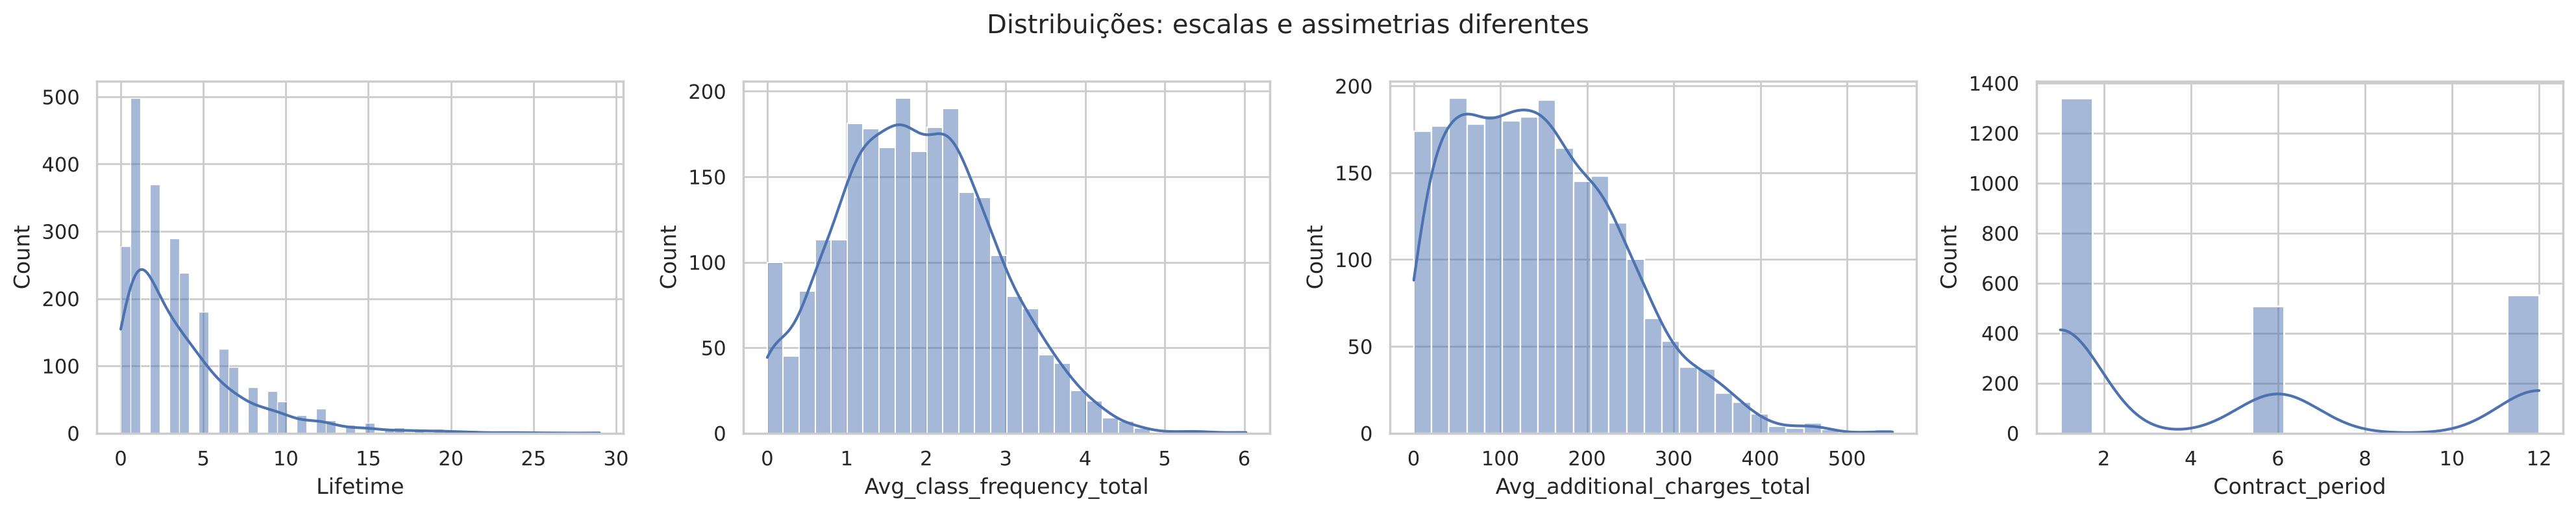

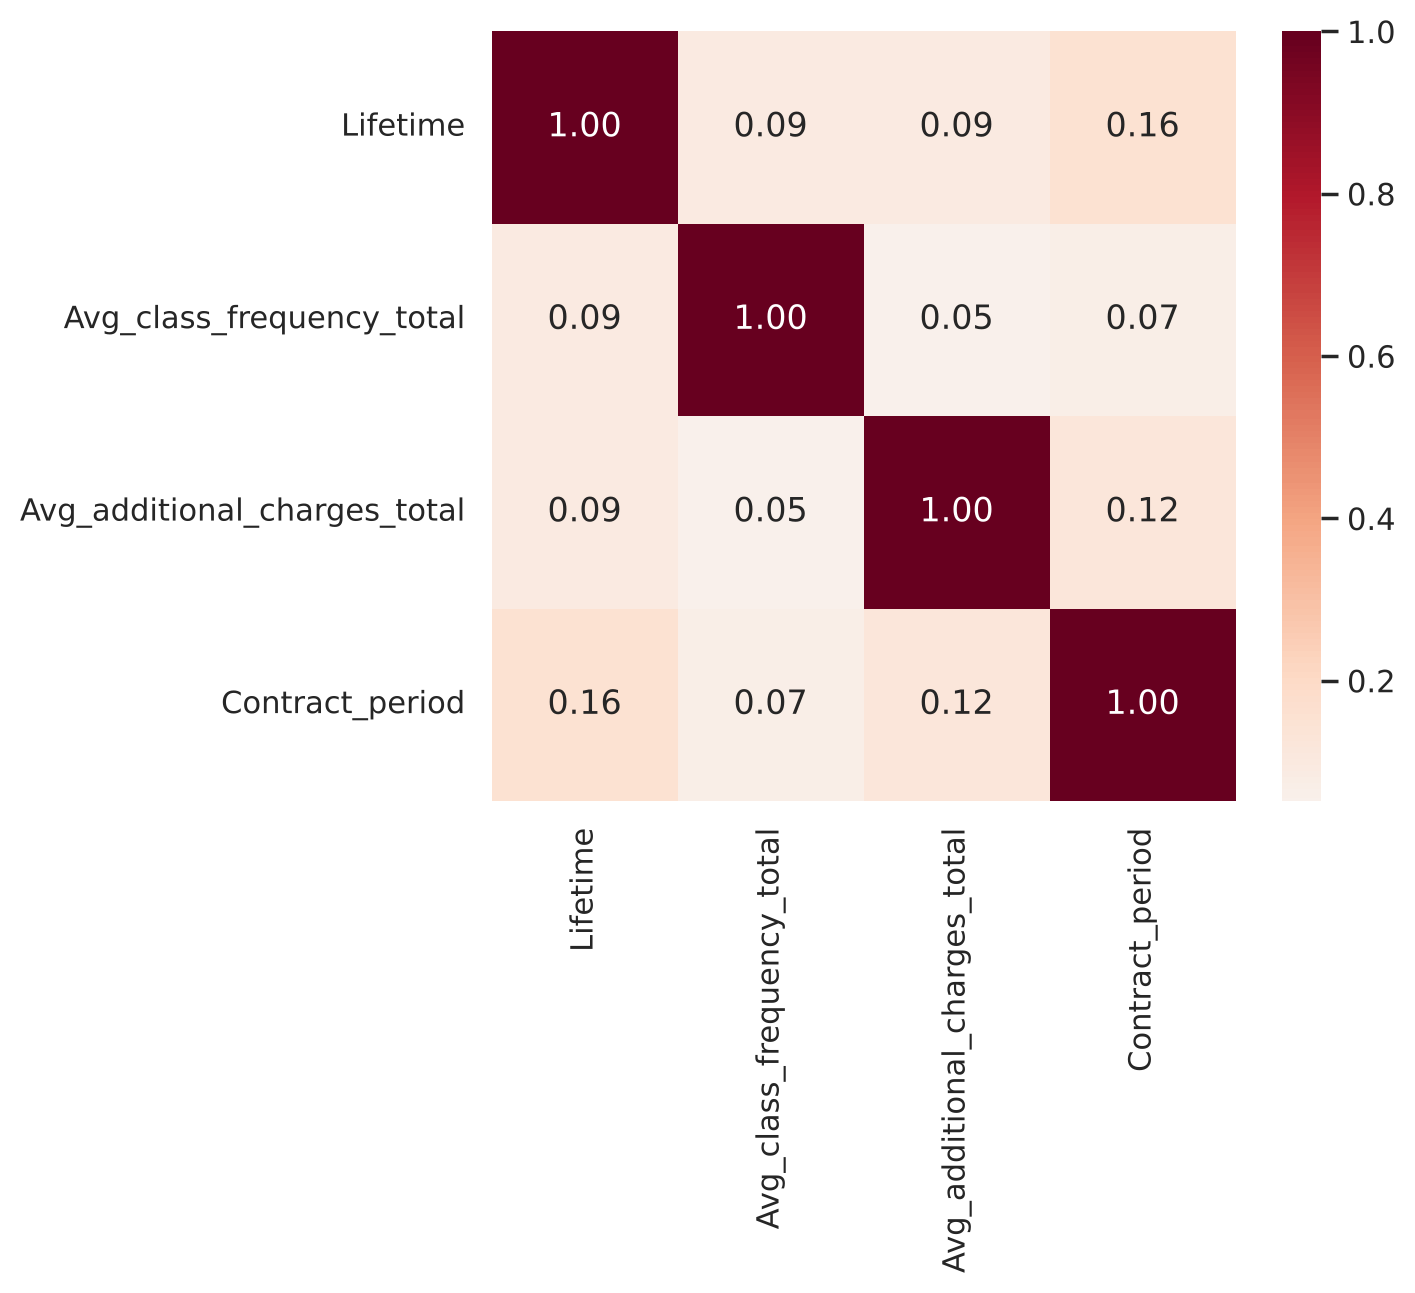

In [43]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, c in zip(ax, vars_k):
    sns.histplot(base_k[c], kde=True, ax=a)
plt.suptitle("Distribuições: escalas e assimetrias diferentes"); plt.tight_layout(); plt.show()
plt.figure(figsize=(6, 5)); sns.heatmap(base_k.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.show()

**Preparação (igual para todos os clientes e todas as comparações de K):**
1. Imputar ausências pela mediana (não há NaN, mas o pipeline fica pronto para clientes novos).
2. `log(1 + x)` em `Lifetime` e `Avg_additional_charges_total` para reduzir a assimetria.
3. Padronizar (Z-score): subtrair a média e dividir pelo desvio.
4. Guardar o pipeline ajustado para aplicar em clientes novos com `transform`.

In [44]:
log_cols = ["Lifetime", "Avg_additional_charges_total"]
outras = [c for c in vars_k if c not in log_cols]
preparacao = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("trans", ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), [0, 1]),
                                 ("id", "passthrough", [2, 3])])),
    ("sc", StandardScaler()),
])
base_ord = base_k[log_cols + outras]
Z = preparacao.fit_transform(base_ord)
print("Médias após preparação:", Z.mean(0).round(2), "| desvios:", Z.std(0).round(2))
print("Assimetria após log:", pd.DataFrame(Z, columns=log_cols + outras).skew().round(2).to_dict())

Médias após preparação: [-0.  0.  0.  0.] | desvios: [1. 1. 1. 1.]
Assimetria após log: {'Lifetime': 0.01, 'Avg_additional_charges_total': -1.48, 'Avg_class_frequency_total': 0.26, 'Contract_period': 0.75}


**Observação:** o log corrigiu `Lifetime` (1,87 → 0,01), mas inverteu a assimetria do gasto extra (0,62 → −1,48), porque "esticou" os valores muito baixos. Isso é uma **escolha de preparação** que muda a semelhança — comparada na seção 7.5.1.

### 7.3 Efeito da escala na divisão encontrada

In [45]:
var_bruta = base_k.var() / base_k.var().sum() * 100
print("% da variância total (dados brutos):"); print(var_bruta.round(1))
km_bruto = KMeans(n_clusters=4, init="k-means++", n_init=20, random_state=SEED).fit(base_k)
km_pad = KMeans(n_clusters=4, init="k-means++", n_init=20, random_state=SEED).fit(Z)
print("\nARI bruto × padronizado (K = 4):", round(adjusted_rand_score(km_bruto.labels_, km_pad.labels_), 3))
pd.concat({"bruto": base_k.groupby(km_bruto.labels_).median(), "padronizado": base_k.groupby(km_pad.labels_).median()}).round(2)

% da variância total (dados brutos):
Lifetime                         0.2
Avg_class_frequency_total        0.0
Avg_additional_charges_total    99.6
Contract_period                  0.2
dtype: float64

ARI bruto × padronizado (K = 4): 0.069


Lifetime  Avg_class_frequency_total  \
bruto       0       2.0                       1.78   
            1       4.0                       2.07   
            2       3.0                       1.83   
            3       3.0                       1.85   
padronizado 0       5.0                       2.53   
            1       1.0                       1.33   
            2       4.0                       1.91   
            3       2.0                       1.87   

               Avg_additional_charges_total  Contract_period  
bruto       0                         44.74              1.0  
            1                        324.86              6.0  
            2                        129.77              1.0  
            3                        217.34              6.0  
padronizado 0                        164.18              1.0  
            1                        136.04              1.0  
            2                        162.25             12.0  
            3                         17.89              1.0

Nos dados brutos, o gasto extra (em reais) responde por **99,6% da variância** — o K-Means bruto agrupa praticamente só por gasto (medianas 45 / 130 / 217 / 325). Após padronizar, todas as variáveis pesam igual e os grupos mudam completamente: **ARI = 0,069** (≈ nenhuma concordância). A escala define o que é "semelhante".

### 7.4 Escolha do número de grupos (K)
- **Soma dos Erros Quadrados:** $J_e = \sum_{i=1}^{c}\sum_{x \in D_i}\lVert x - m_i\rVert^2$ (a `inertia_` do K-Means = $\mathrm{tr}(S_W)$).
- **Dispersão within:** $S_W = \sum_i \sum_{x \in D_i}(x-m_i)(x-m_i)^T$ → compactação (quer-se **baixo**).
- **Dispersão between:** $S_B = \sum_i n_i (m_i - m)(m_i - m)^T$ → afastamento entre centros (quer-se **alto**).
- $S_T = S_W + S_B$ (dispersão total, constante). Usamos $\mathrm{tr}(S_W)/\mathrm{tr}(S_B)$ (menor = melhor) e a silhueta.
- **Configuração:** `init="k-means++"` e `n_init=20` para reduzir o impacto da inicialização aleatória.

In [46]:
def dispersao(Z_, rot):
    m = Z_.mean(0); sw = sb = 0.0
    for k in np.unique(rot):
        Zi = Z_[rot == k]; mi = Zi.mean(0)
        sw += ((Zi - mi) ** 2).sum(); sb += len(Zi) * ((mi - m) ** 2).sum()
    return sw, sb

linhas_k = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=SEED).fit(Z)
    sw, sb = dispersao(Z, km.labels_)
    linhas_k.append({"K": k, "Je_inercia": km.inertia_, "tr_Sw": sw, "tr_Sb": sb, "Sw/Sb": sw / sb,
                     "silhueta": silhouette_score(Z, km.labels_), "menor_grupo": np.bincount(km.labels_).min()})
tab_k = pd.DataFrame(linhas_k).set_index("K")
print("tr(S_T) =", round((Z ** 2).sum(), 1), "(constante = tr(Sw) + tr(Sb))")
tab_k.round(3)

tr(S_T) = 9600.0 (constante = tr(Sw) + tr(Sb))


,Je_inercia,tr_Sw,tr_Sb,Sw/Sb,silhueta,menor_grupo
K,,,,,,
2,7377.859,7377.858,2222.142,3.320,0.249,844
3,6018.916,6018.881,3581.119,1.681,0.240,587
4,4931.513,4931.507,4668.493,1.056,0.259,298
5,4301.457,4301.419,5298.581,0.812,0.248,268
6,3915.502,3915.502,5684.498,0.689,0.244,254
7,3657.425,3657.425,5942.575,0.615,0.212,244
8,3449.991,3449.991,6150.009,0.561,0.212,145
9,3271.078,3271.078,6328.922,0.517,0.210,159
10,3091.821,3091.780,6508.220,0.475,0.216,122


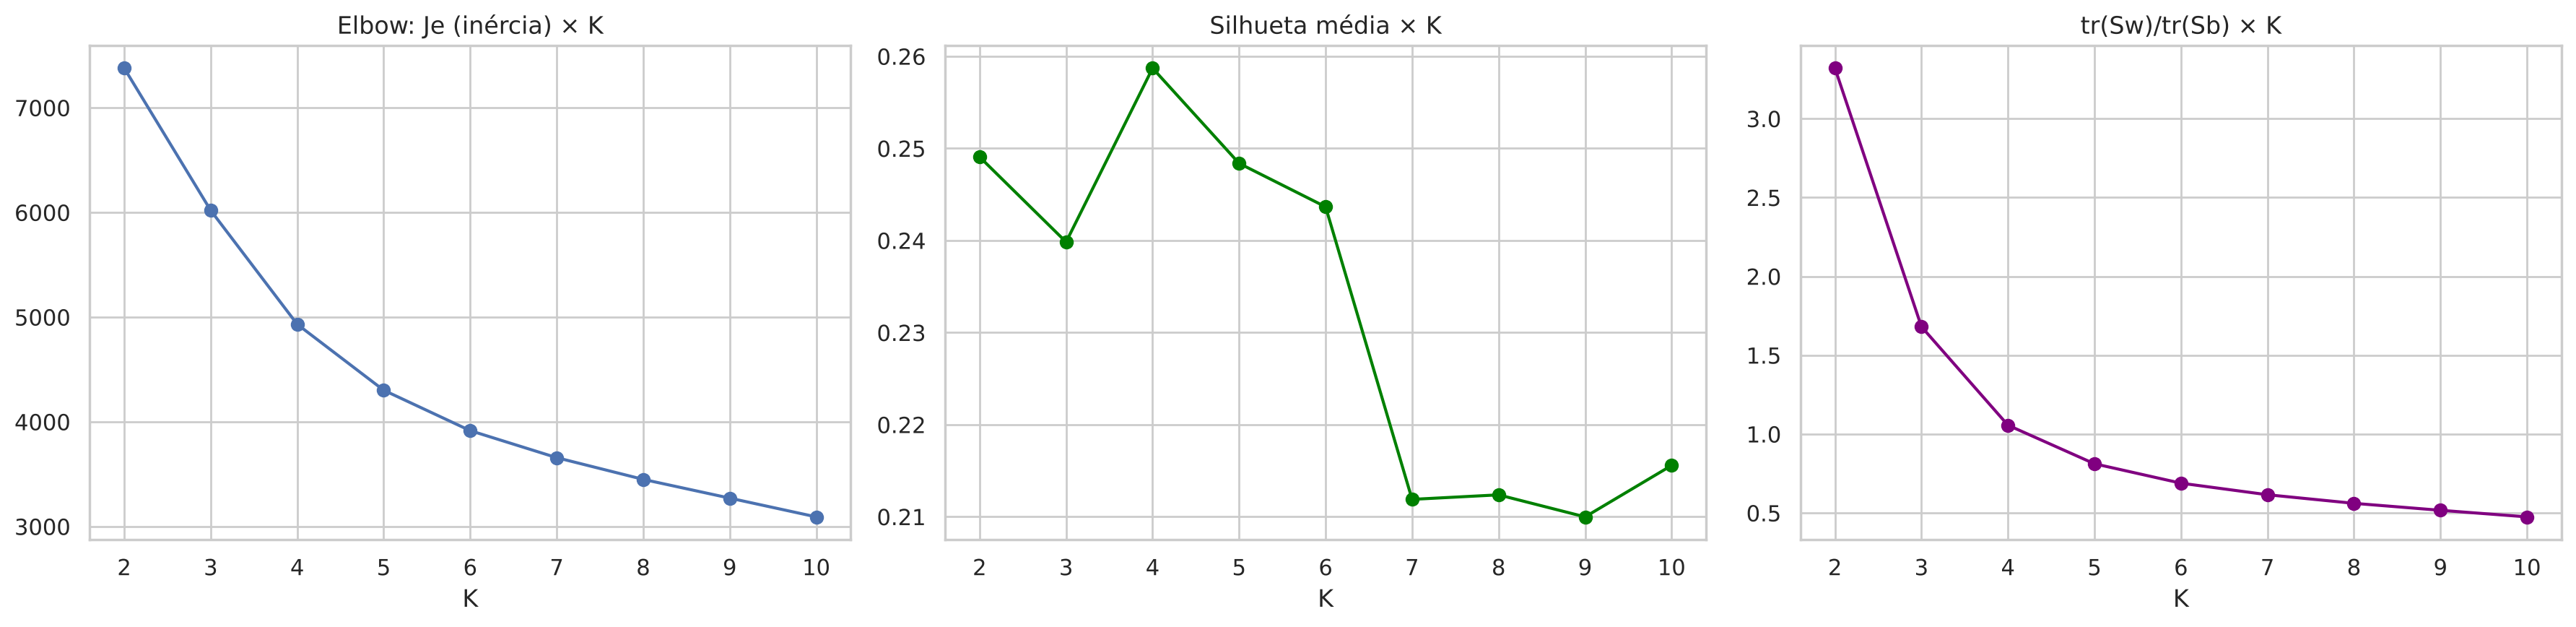

In [47]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(tab_k.index, tab_k["Je_inercia"], marker="o"); ax[0].set_title("Elbow: Je (inércia) × K")
ax[1].plot(tab_k.index, tab_k["silhueta"], marker="o", c="green"); ax[1].set_title("Silhueta média × K")
ax[2].plot(tab_k.index, tab_k["Sw/Sb"], marker="o", c="purple"); ax[2].set_title("tr(Sw)/tr(Sb) × K")
for a in ax: a.set_xlabel("K")
plt.tight_layout(); plt.show()

**Escolha de K = 4:**
- O **cotovelo** não é nítido (Je cai de forma suave) — por isso confirmamos com outros critérios.
- A **silhueta** é máxima em K = 4 (0,259).
- $\mathrm{tr}(S_W)/\mathrm{tr}(S_B)$ cai sempre com K (mais grupos = mais compactos) — sozinho não escolhe K; em K = 4 within e between ficam praticamente iguais (1,06).
- K = 4 também é o mais **interpretável** (seção 7.7) e estável (7.5).
- **Silhueta ≈ 0,26 é modesta:** há estrutura, mas os grupos **não são naturalmente bem separados** — clientes variam de forma contínua. A divisão é útil, não "verdadeira".

In [48]:
K = 4
modelo_k = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=SEED).fit(Z)
rot = modelo_k.labels_
sw, sb = dispersao(Z, rot)
print(f"K = {K} | silhueta = {silhouette_score(Z, rot):.3f} | Sw = {sw:.1f} | Sb = {sb:.1f} | Sw/Sb = {sw/sb:.3f}")
print("Tamanhos:", dict(zip(*np.unique(rot, return_counts=True))))

K = 4 | silhueta = 0.259 | Sw = 4931.5 | Sb = 4668.5 | Sw/Sb = 1.056
Tamanhos: {np.int32(0): np.int64(711), np.int32(1): np.int64(817), np.int32(2): np.int64(574), np.int32(3): np.int64(298)}


### 7.5 Avaliação: separação, estabilidade e casos de fronteira

In [49]:
ari_seeds = []
for s in range(20):
    r = KMeans(n_clusters=K, init="k-means++", n_init=1, random_state=s).fit(Z).labels_
    ari_seeds.append(adjusted_rand_score(rot, r))
print(f"Inicialização (20 sementes, n_init=1): ARI médio = {np.mean(ari_seeds):.3f} | mínimo = {np.min(ari_seeds):.3f}")

rng = np.random.default_rng(SEED); ari_amostra = []
for _ in range(30):
    idx = rng.choice(len(Z), size=int(0.8 * len(Z)), replace=False)
    r = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=SEED).fit(Z[idx])
    ari_amostra.append(adjusted_rand_score(rot[idx], r.labels_))
print(f"Subamostras de 80% (30x): ARI médio = {np.mean(ari_amostra):.3f} | mínimo = {np.min(ari_amostra):.3f}")

Inicialização (20 sementes, n_init=1): ARI médio = 0.892 | mínimo = 0.453


Subamostras de 80% (30x): ARI médio = 0.958 | mínimo = 0.892


Com `n_init=20` a solução é reprodutível; com uma única inicialização o ARI médio é 0,89, mas o **mínimo cai para 0,45** — prova do impacto da inicialização aleatória e da importância de rodar várias vezes. Em subamostras de 80%, ARI médio 0,96 (mínimo 0,89) → **estrutura estável**.

In [50]:
sil = silhouette_samples(Z, rot)
print(f"Clientes com silhueta < 0,20 (fronteira): {(sil < 0.2).sum()} ({(sil < 0.2).mean():.1%}) | negativa: {(sil < 0).sum()}")
pd.DataFrame({"grupo": rot, "sil": sil}).groupby("grupo")["sil"].agg(["mean", "min", lambda s: (s < 0.2).sum()]).rename(columns={"<lambda_0>": "n_fronteira"}).round(3)

Clientes com silhueta < 0,20 (fronteira): 787 (32.8%) | negativa: 108


,mean,min,n_fronteira
grupo,,,
0,0.234,-0.035,278
1,0.313,0.012,195
2,0.257,-0.107,154
3,0.173,-0.109,160


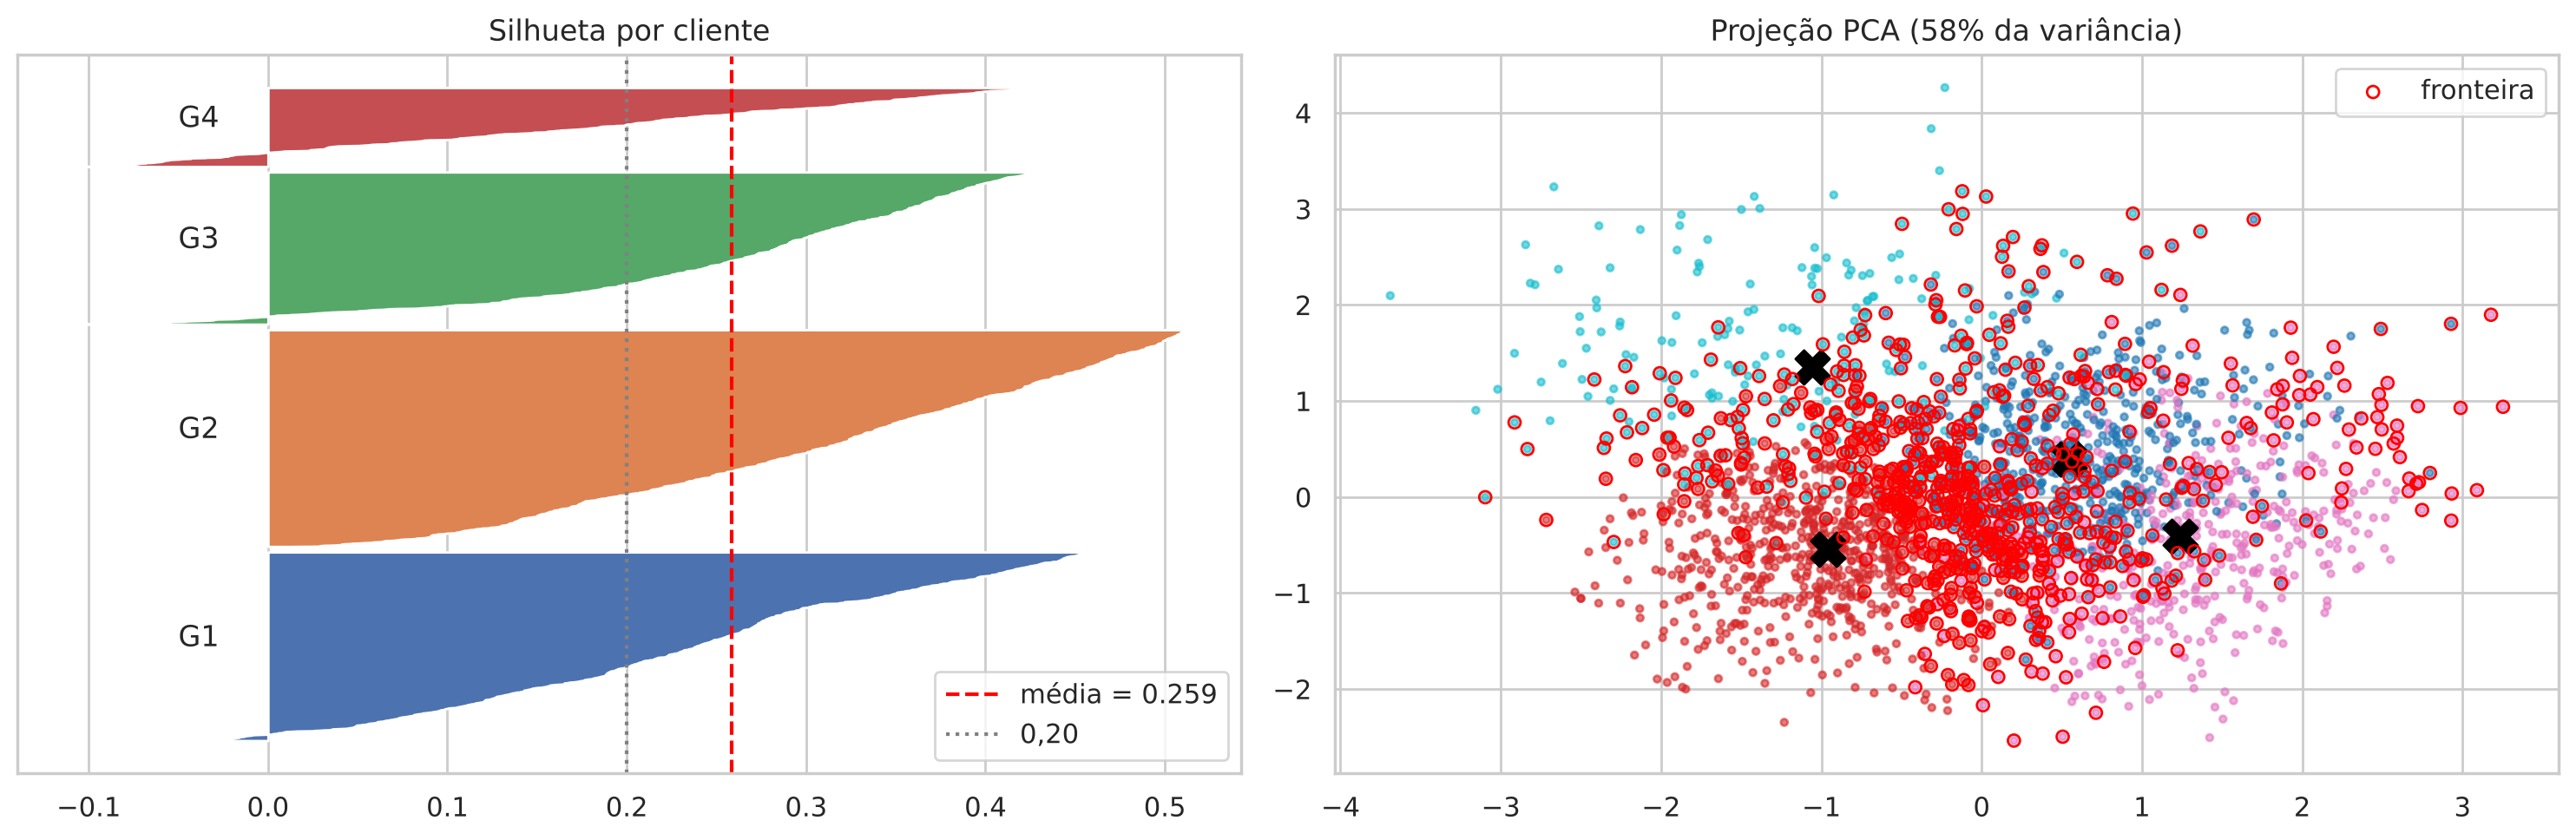

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
y0 = 0
for k in range(K):
    s = np.sort(sil[rot == k]); ax[0].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s); ax[0].text(-0.05, y0 + len(s) / 2, f"G{k+1}"); y0 += len(s) + 20
ax[0].axvline(sil.mean(), c="red", ls="--", label=f"média = {sil.mean():.3f}"); ax[0].axvline(0.2, c="gray", ls=":", label="0,20")
ax[0].set_title("Silhueta por cliente"); ax[0].legend(); ax[0].set_yticks([])
from sklearn.decomposition import PCA
pca = PCA(2, random_state=SEED).fit(Z); P = pca.transform(Z); C2 = pca.transform(modelo_k.cluster_centers_)
ax[1].scatter(P[:, 0], P[:, 1], c=rot, cmap="tab10", s=8, alpha=.6)
ax[1].scatter(C2[:, 0], C2[:, 1], c="black", marker="X", s=200)
ax[1].scatter(P[sil < 0.2, 0], P[sil < 0.2, 1], facecolors="none", edgecolors="red", s=25, label="fronteira")
ax[1].set_title(f"Projeção PCA ({pca.explained_variance_ratio_.sum():.0%} da variância)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Casos de fronteira:** 787 clientes (33%) têm silhueta < 0,20 e 108 têm silhueta negativa (estão mais perto de outro grupo). O G4 é o menos coeso (silhueta média 0,17). Esses clientes devem ser tratados com cautela ao aplicar ações por perfil.

#### 7.5.1 Comparação de escolhas de preparação

In [52]:
def rodar(log_c):
    b = base_k.copy(); b[log_c] = np.log1p(b[log_c]); Zx = StandardScaler().fit_transform(b)
    l = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=SEED).fit(Zx).labels_
    return {"silhueta": silhouette_score(Zx, l), "ARI_vs_escolhida": adjusted_rand_score(rot, l),
            "churn_min": y_train.groupby(l).mean().min(), "churn_max": y_train.groupby(l).mean().max()}
pd.DataFrame({"log Lifetime + gasto (escolhida)": rodar(log_cols), "log só Lifetime": rodar(["Lifetime"]),
              "sem log": rodar([])}).T.round(3)

,silhueta,ARI_vs_escolhida,churn_min,churn_max
log Lifetime + gasto (escolhida),0.259,1.000,0.017,0.591
log só Lifetime,0.232,0.522,0.020,0.670
sem log,0.251,0.334,0.000,0.481


A preparação escolhida tem a **maior silhueta** (0,259); "log só Lifetime" separa um pouco mais o churn (2% a 67%), mas com grupos menos coesos (0,232) — e o churn não pode ser o critério de escolha, pois não participa do agrupamento. As alternativas geram divisões bem diferentes (ARI 0,33–0,52): **a preparação é parte do modelo** e precisa ser justificada e fixada.

### 7.6 Variáveis que diferenciam os grupos
Duas medidas:
- **% de separação por variável** = $100 \times (1 - \text{variação dentro} / \text{variação total})$ → maior = perfis mais distintos nessa variável.
- **ARI após retirada:** refaz o K-Means sem a variável e compara com a divisão original → menor ARI = a divisão mudou mais (a variável era estrutural).

In [53]:
nomes_z = log_cols + outras
sep = {}
for j, c in enumerate(nomes_z):
    tot = ((Z[:, j] - Z[:, j].mean()) ** 2).sum()
    den = sum(((Z[rot == k, j] - Z[rot == k, j].mean()) ** 2).sum() for k in range(K))
    sep[c] = 100 * (1 - den / tot)
ari_ret = {}
for j, c in enumerate(nomes_z):
    r = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=SEED).fit(np.delete(Z, j, axis=1)).labels_
    ari_ret[c] = adjusted_rand_score(rot, r)
pd.DataFrame({"%_separacao": sep, "ARI_sem_a_variavel": ari_ret}).sort_values("%_separacao", ascending=False).round(3)

,%_separacao,ARI_sem_a_variavel
Contract_period,75.300,0.440
Avg_additional_charges_total,57.676,0.567
Lifetime,35.708,0.586
Avg_class_frequency_total,25.836,0.632


`Contract_period` é a variável que mais separa os perfis (75%) e a mais estrutural (sem ela, ARI cai para 0,44); depois vem o gasto extra (58%). A frequência é a que menos diferencia os grupos. Lembrando: isso é "importante **para a divisão**", não "importante para prever churn" (seção 5).

### 7.7 Interpretação dos perfis
Em cada célula: **mediana [P25 – P75]**. As características são típicas do grupo; os integrantes não são idênticos. Os **nomes vêm depois** da leitura dos perfis.

In [54]:
def resumo_perfil(d, g, cols):
    out = {}
    for c in cols:
        q = d.groupby(g)[c].quantile([.25, .5, .75]).unstack()
        out[c] = q.apply(lambda r: f"{r[0.5]:.2f} [{r[0.25]:.2f} – {r[0.75]:.2f}]", axis=1)
    t = pd.DataFrame(out); t.insert(0, "n", d.groupby(g).size()); return t

perf = base_k.assign(grupo=rot + 1)
resumo_perfil(perf, "grupo", vars_k)

,n,Lifetime,Avg_class_frequency_total,Avg_additional_charges_total,Contract_period
grupo,,,,,
1,711,5.00 [3.00 – 8.00],2.53 [1.98 – 3.10],164.18 [107.45 – 231.44],1.00 [1.00 – 6.00]
2,817,1.00 [0.00 – 2.00],1.33 [0.83 – 1.76],136.04 [85.67 – 198.07],1.00 [1.00 – 1.00]
3,574,4.00 [2.00 – 7.00],1.91 [1.08 – 2.63],162.25 [92.43 – 228.23],12.00 [12.00 – 12.00]
4,298,2.00 [1.00 – 4.00],1.87 [1.21 – 2.38],17.89 [8.38 – 28.70],1.00 [1.00 – 6.00]


In [55]:
extra = df.loc[X_train.index, ["Age", "Partner", "Promo_friends", "Group_visits", "Near_Location", "Avg_class_frequency_current_month"]].assign(grupo=rot + 1)
extra["freq_drop"] = dfe.loc[X_train.index, "freq_drop"].values
extra.groupby("grupo").mean().round(2)

,Age,Partner,Promo_friends,Group_visits,Near_Location,Avg_class_frequency_current_month,freq_drop
grupo,,,,,,,
1,29.80,0.44,0.29,0.42,0.86,2.53,-0.02
2,28.25,0.39,0.24,0.33,0.79,1.06,-0.25
3,29.85,0.69,0.46,0.53,0.93,1.87,-0.01
4,28.90,0.46,0.27,0.34,0.79,1.68,-0.17


Essas colunas **descrevem** os perfis, mas **não determinaram** a formação dos grupos.

**Leitura dos perfis e nomes descritivos:**
| Grupo | Perfil típico | Nome |
|---|---|---|
| G1 (711) | ~5 meses de casa, **maior frequência** (2,5 aulas/sem), contrato curto | **Frequentadores fiéis** |
| G2 (817) | **novatos** (~1 mês), **baixa frequência** (1,3) e **em queda** (freq_drop −0,25), contrato de 1 mês | **Novatos em desengajamento** |
| G3 (574) | **contrato anual**, mais parceiros/indicações e aulas em grupo | **Anuais comprometidos** |
| G4 (298) | **quase sem gasto extra** (mediana R$ 18), ~2 meses de casa | **Só-treino, sem consumo extra** |

Os nomes são hipóteses descritivas, sujeitas à variação interna mostrada nos intervalos.

In [56]:
MAPA = {0: "G1 Frequentadores fiéis", 1: "G2 Novatos em desengajamento", 2: "G3 Anuais comprometidos", 3: "G4 Só-treino, sem consumo extra"}
nomes_g = np.array([MAPA[k] for k in rot])
pd.Series(nomes_g).value_counts()

G2 Novatos em desengajamento       817
G1 Frequentadores fiéis            711
G3 Anuais comprometidos            574
G4 Só-treino, sem consumo extra    298
Name: count, dtype: int64

### 7.8 Utilidade da segmentação
O `Churn` não participou do agrupamento. Se a taxa de abandono for muito diferente entre os grupos, a segmentação tem **valor prático** para a academia.

                                   n  taxa_churn
grupo                                           
G1 Frequentadores fiéis          711       0.042
G2 Novatos em desengajamento     817       0.591
G3 Anuais comprometidos          574       0.017
G4 Só-treino, sem consumo extra  298       0.383
Taxa geral: 0.265


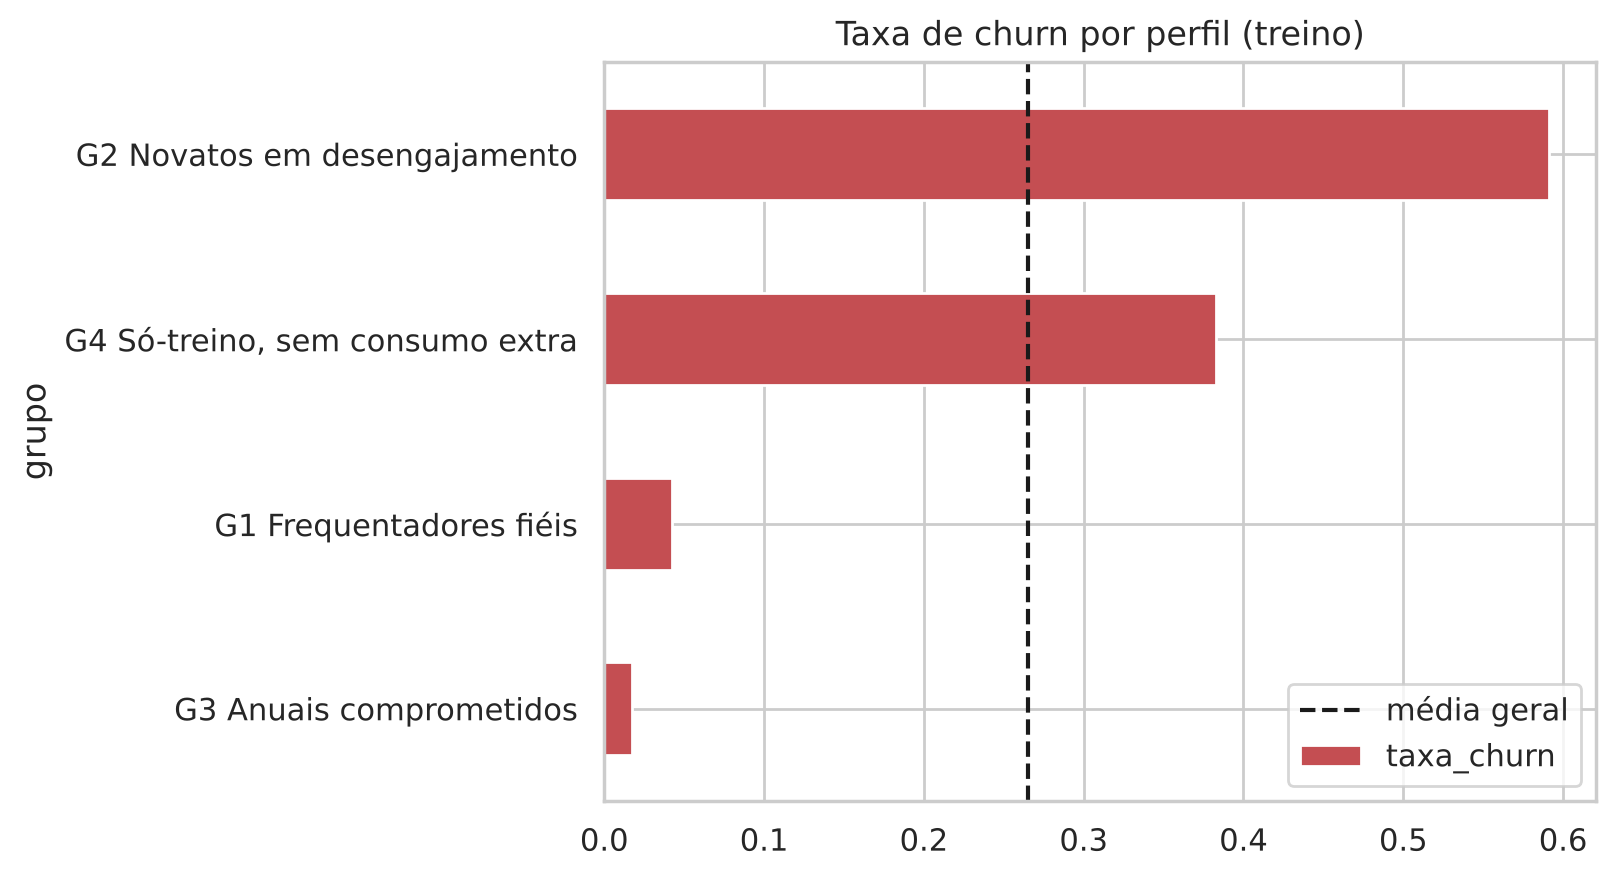

In [57]:
churn_g = pd.DataFrame({"grupo": nomes_g, "Churn": y_train.values}).groupby("grupo")["Churn"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "taxa_churn"})
print(churn_g.round(3)); print("Taxa geral:", round(y_train.mean(), 3))
churn_g["taxa_churn"].sort_values().plot.barh(color="#C44E52"); plt.axvline(y_train.mean(), ls="--", c="k", label="média geral")
plt.title("Taxa de churn por perfil (treino)"); plt.legend(); plt.show()

**A segmentação é útil:** sem usar o `Churn`, o K-Means separou perfis com taxas de abandono muito diferentes: **59%** nos novatos em desengajamento e **38%** no só-treino, contra **4%** e **2%** nos fiéis e anuais (média geral 26,5%). Hipóteses de ação (a testar, não conclusões): acompanhamento nas primeiras semanas para G2; ofertas de serviços extras para G4; incentivo à migração para contrato anual.

### 7.9 Aplicação a novos clientes
O cliente novo passa pela **mesma** preparação aprendida no treino (`transform`) e recebe o **centroide mais próximo** (`predict`). Usar `fit_transform` recalcularia médias/desvios com os dados novos e mudaria o significado das coordenadas — os centroides deixariam de valer. Também monitoramos clientes **muito distantes** de todos os centros (perfil que a segmentação não cobre).

In [58]:
Zn = preparacao.transform(novos_k[log_cols + outras])
rot_n = modelo_k.predict(Zn)
dist_treino = modelo_k.transform(Z).min(1); dist_novos = modelo_k.transform(Zn).min(1)
lim = np.quantile(dist_treino, 0.99)
print(f"Clientes novos (teste): {len(Zn)} | distantes (> P99 do treino = {lim:.2f}): {(dist_novos > lim).sum()}")
comp = pd.DataFrame({"treino_%": pd.Series(nomes_g).value_counts(normalize=True),
                     "novos_%": pd.Series([MAPA[k] for k in rot_n]).value_counts(normalize=True)})
comp["churn_novos"] = pd.Series(y_test.values).groupby([MAPA[k] for k in rot_n]).mean()
comp.round(3)

Clientes novos (teste): 800 | distantes (> P99 do treino = 2.76): 16


,treino_%,novos_%,churn_novos
G1 Frequentadores fiéis,0.296,0.265,0.047
G2 Novatos em desengajamento,0.340,0.352,0.582
G3 Anuais comprometidos,0.239,0.269,0.033
"G4 Só-treino, sem consumo extra",0.124,0.114,0.341


Nos 800 clientes novos (teste), a proporção de cada perfil e a taxa de churn por perfil se mantêm (G2: 58%, G4: 34%, G1: 5%, G3: 3%) → os perfis **generalizam**. 16 clientes estão além do P99 de distância do treino — devem ser monitorados (perfil não coberto).

In [59]:
cent = pd.DataFrame(preparacao.named_steps["sc"].inverse_transform(modelo_k.cluster_centers_), columns=log_cols + outras)
cent[log_cols] = np.expm1(cent[log_cols]); cent.index = [MAPA[k] for k in range(K)]
cent.round(2)

,Lifetime,Avg_additional_charges_total,Avg_class_frequency_total,Contract_period
G1 Frequentadores fiéis,4.84,151.90,2.55,2.65
G2 Novatos em desengajamento,1.07,127.97,1.31,1.95
G3 Anuais comprometidos,3.84,140.56,1.88,11.51
"G4 Só-treino, sem consumo extra",2.26,14.15,1.85,3.09


### 7.10 O cluster ajuda a prever o churn?
Adicionamos o grupo (One-Hot) como atributo e comparamos o F1 em validação cruzada no treino, com e sem ele.

In [60]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
Xc = X_train.assign(grupo=rot.astype(str))
prep_c = ColumnTransformer([("num", StandardScaler(), col_num), ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat + ["grupo"])])
comp_feat = {}
for nome, est in [("Regressão Logística", LogisticRegression(max_iter=2000, class_weight="balanced", C=10)),
                  ("Gradient Boosting", clone(modelos["Gradient Boosting"].named_steps["clf"]))]:
    sem = cross_val_score(Pipeline([("prep", prep_escala), ("clf", est)]), X_train, y_train, cv=cv, scoring="f1").mean()
    com = cross_val_score(Pipeline([("prep", prep_c), ("clf", clone(est))]), Xc, y_train, cv=cv, scoring="f1").mean()
    comp_feat[nome] = {"F1_CV_sem_cluster": sem, "F1_CV_com_cluster": com, "ganho": com - sem}
pd.DataFrame(comp_feat).T.round(4)

,F1_CV_sem_cluster,F1_CV_com_cluster,ganho
Regressão Logística,0.8432,0.8454,0.0022
Gradient Boosting,0.9134,0.9078,-0.0056


O cluster praticamente **não melhora** a previsão (+0,002 na Logística, −0,006 no GB): os modelos supervisionados já extraem essa informação diretamente dos atributos. O valor do K-Means aqui é **descritivo e estratégico** (organizar ações por perfil), não preditivo.

### 7.11 Limitações
- Obter uma divisão **não prova** que existam grupos naturais; o K-Means sempre devolve K grupos.
- A taxa de churn diferente entre perfis é **associação**: clientes do perfil de alto churn podem sair por motivos que não estão nos dados.
- Para afirmar que uma ação de retenção (ex.: desconto na renovação) **reduz** o abandono, seria preciso um **experimento aleatorizado**: congelar os perfis, sortear a oferta dentro de cada grupo, medir o churn depois e comparar com intervalo de confiança.